# PRCP-1008 · NBA Shot Selection — Kobe Bryant Shot Prediction

**Domain:** Sports analytics  **Target:** `shot_made_flag` (1 = made, 0 = missed)

| Project requirement | Where it is answered |
|---|---|
| **Task 1** – Complete data analysis report | Sections 3 – 6 (plus 23, 24) |
| **Task 2** – Help stakeholders build better game strategy / best model by accuracy & F1 | Sections 9 – 18, 23, 27 |
| **Task 3** – Shot prediction model (score / not score) | Sections 7 – 19 |
| **Model Comparison Report** | Section 18 (statistical comparison in Section 20) |
| **Report on Challenges faced** | Section 26 |

### Design decisions (and why)
1. **Rows with an empty target are set aside for training and evaluation.** The raw file contains rows whose `shot_made_flag` is empty. A supervised model cannot learn from them and they cannot be used to measure accuracy, but the *final trained model can score them* — this is done in Section 19.
2. **No random-split-only evaluation.** Shots from the same game share context, so a random split lets the model "see" the game it is tested on. Three schemes (random / grouped-by-game / chronological) are compared and the **chronological** hold-out is the headline number, because it mimics predicting future shots.
3. **The hold-out set is never used for any selection.** Model choice, ensemble choice, calibration method, hyper-parameters and the decision threshold are all selected with grouped cross-validation on the *development* (earlier) data. Hold-out predictions are computed for *reporting* only. Sections 20 and 22–24 analyse the hold-out *after* selection and change no decision.
4. **A predefined selection score aligned with the assignment:**  `SelectionScore = (Accuracy + F1) / 2`, measured on development-set out-of-fold predictions at each model's own out-of-fold-optimised threshold. Log-loss and ROC-AUC are the additional criteria (tie-break: Section 12).
5. **Stacking is validated with nested, group-aware cross-fitting** (Section 11) so that no base-model prediction used to train the meta-model comes from a model that saw the meta-validation fold.
6. **Tools must earn their place.** Gradient boosting, Optuna, SHAP, calibration, Pandera, MLflow and drift monitoring each address a specific problem; no neural networks (nothing in the data requires them).

## 1. Setup and reproducibility
All dependencies are installed explicitly so the notebook runs in a fresh environment

In [1]:
%pip install -q xgboost lightgbm catboost shap optuna pandera mlflow plotly statsmodels scikit-learn scipy seaborn matplotlib joblib

In [2]:
# Optional: Evidently AI (HTML drift report in Section 24). The notebook still runs if this install fails.
%pip install -q evidently

In [3]:
import os, re, sys, glob, zipfile, urllib.request, warnings, time, platform, pathlib
import importlib.metadata as importlib_metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from matplotlib.patches import Circle, Rectangle, Arc
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.contingency_tables import mcnemar
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, IsolationForest)
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, log_loss, brier_score_loss, confusion_matrix,
                             roc_curve, precision_recall_curve, average_precision_score)
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import optuna, shap, joblib

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

SEED = 42
N_TRIALS = int(os.environ.get("NB_TRIALS", 25))          # Optuna trials per model (Section 10)
N_NEST = int(os.environ.get("NB_NEST_TRIALS", 8))        # Optuna trials per outer fold (Section 21)
CAT_ITERS = int(os.environ.get("NB_CAT_ITERS", 400))     # CatBoost iterations
N_BOOT = int(os.environ.get("NB_BOOT", 500))             # bootstrap resamples
np.random.seed(SEED)

PKGS = ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "xgboost", "lightgbm", "catboost", "optuna",
        "shap", "pandera", "mlflow", "plotly", "matplotlib", "seaborn", "joblib", "evidently"]
VERSIONS = {}
for p_ in PKGS:
    try:
        VERSIONS[p_] = importlib_metadata.version(p_)
    except Exception:
        VERSIONS[p_] = "not installed"
print("Python", sys.version.split()[0], "|", platform.platform())
display(pd.Series(VERSIONS, name="version").to_frame())
with open("requirements_used.txt", "w") as fh:
    fh.write("\n".join(f"{k}=={v}" for k, v in VERSIONS.items() if v != "not installed") + "\n")

Python 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39


,version
numpy,2.4.6
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1
statsmodels,0.15.0
xgboost,3.4.1
lightgbm,4.6.0
catboost,1.2.10
optuna,5.0.0
shap,0.54.1


## 2. Data ingestion
The cell looks for the CSV locally, then downloads the project zip, then (Colab only) asks for an upload.

In [4]:
DATA_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1008-NBAShotSelection.zip"

def find_csv(folder="."):
    paths = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
    for p in sorted(paths, key=os.path.getsize, reverse=True):
        try:
            if "shot_made_flag" in pd.read_csv(p, nrows=1).columns:
                return p
        except Exception:
            continue
    return None

csv_path = find_csv(".")
if csv_path is None:
    try:
        os.makedirs("data_raw", exist_ok=True)
        zpath, _ = urllib.request.urlretrieve(DATA_URL, "data_raw/kobe.zip")
        with zipfile.ZipFile(zpath) as z:
            z.extractall("data_raw")
        csv_path = find_csv("data_raw")
    except Exception as e:
        print("Automatic download failed:", e)
if csv_path is None:
    from google.colab import files          # only works inside Colab
    print("Upload the dataset CSV (data.csv) or the zip:")
    up = files.upload()
    for name in up:
        if name.endswith(".zip"):
            with zipfile.ZipFile(name) as z:
                z.extractall("data_raw")
    csv_path = find_csv(".")
assert csv_path is not None, "Could not locate the dataset CSV"
print("Using:", csv_path)

raw = pd.read_csv(csv_path)
raw["game_date"] = pd.to_datetime(raw["game_date"])
print("Shape:", raw.shape)
raw.head()

Using: data_raw/Data/data.csv
Shape: (30697, 25)


,action_type,combined_shot_type,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,playoffs,season,seconds_remaining,shot_distance,shot_made_flag,shot_type,shot_zone_area,shot_zone_basic,shot_zone_range,team_id,team_name,game_date,matchup,opponent,shot_id
0,Jump Shot,Jump Shot,10,20000012,33.9723,167,72,-118.1028,10,1,0,2000-01,27,18,NaN,2PT Field Goal,Right Side(R),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,1
1,Jump Shot,Jump Shot,12,20000012,34.0443,-157,0,-118.4268,10,1,0,2000-01,22,15,0.0,2PT Field Goal,Left Side(L),Mid-Range,8-16 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,2
2,Jump Shot,Jump Shot,35,20000012,33.9093,-101,135,-118.3708,7,1,0,2000-01,45,16,1.0,2PT Field Goal,Left Side Center(LC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,3
3,Jump Shot,Jump Shot,43,20000012,33.8693,138,175,-118.1318,6,1,0,2000-01,52,22,0.0,2PT Field Goal,Right Side Center(RC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,4
4,Driving Dunk Shot,Dunk,155,20000012,34.0443,0,0,-118.2698,6,2,0,2000-01,19,0,1.0,2PT Field Goal,Center(C),Restricted Area,Less Than 8 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,5


## 3. Data validation (Pandera) and data quality assessment (Task 1 · part 1)

In [5]:
# Declarative data contract. Violations are REPORTED (lazy validation) rather than silently ignored; the notebook then continues.
try:
    import pandera.pandas as pa
except ImportError:
    import pandera as pa

ZONE_BASIC = ["Mid-Range", "Restricted Area", "In The Paint (Non-RA)", "Above the Break 3", "Right Corner 3", "Left Corner 3", "Backcourt"]
ZONE_AREA = ["Right Side(R)", "Left Side(L)", "Left Side Center(LC)", "Right Side Center(RC)", "Center(C)", "Back Court(BC)"]
ZONE_RANGE = ["Less Than 8 ft.", "8-16 ft.", "16-24 ft.", "24+ ft.", "Back Court Shot"]

schema = pa.DataFrameSchema({
    "shot_id": pa.Column(unique=True, nullable=False),
    "game_id": pa.Column(nullable=False),
    "game_date": pa.Column(checks=pa.Check.in_range(pd.Timestamp("1996-01-01"), pd.Timestamp("2016-12-31"))),
    "loc_x": pa.Column(checks=pa.Check.in_range(-300, 300)),
    "loc_y": pa.Column(checks=pa.Check.in_range(-100, 900)),
    "shot_distance": pa.Column(checks=pa.Check.in_range(0, 100)),
    "minutes_remaining": pa.Column(checks=pa.Check.in_range(0, 12)),
    "seconds_remaining": pa.Column(checks=pa.Check.in_range(0, 59)),
    "period": pa.Column(checks=pa.Check.in_range(1, 10)),
    "playoffs": pa.Column(checks=pa.Check.isin([0, 1])),
    "shot_made_flag": pa.Column(checks=pa.Check.isin([0, 1]), nullable=True),
    "shot_type": pa.Column(checks=pa.Check.isin(["2PT Field Goal", "3PT Field Goal"])),
    "shot_zone_basic": pa.Column(checks=pa.Check.isin(ZONE_BASIC)),
    "shot_zone_area": pa.Column(checks=pa.Check.isin(ZONE_AREA)),
    "shot_zone_range": pa.Column(checks=pa.Check.isin(ZONE_RANGE)),
}, strict=False)

try:
    schema.validate(raw, lazy=True)
    print("Pandera validation PASSED: all columns satisfy the data contract.")
except pa.errors.SchemaErrors as err:
    print("Pandera validation found", len(err.failure_cases), "failing values. First rows:")
    display(err.failure_cases.head(20))
    print("The notebook continues; inspect these before trusting downstream results.")

Pandera validation PASSED: all columns satisfy the data contract.


In [6]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "n_unique": raw.nunique(),
})
display(quality)

print("Duplicate full rows        :", raw.duplicated().sum())
print("shot_id unique             :", raw["shot_id"].is_unique)
constant_cols = [c for c in raw.columns if raw[c].nunique(dropna=False) == 1]
print("Constant columns           :", constant_cols)
print("Games (game_id)            :", raw["game_id"].nunique())
print("Date range                 :", raw["game_date"].min().date(), "->", raw["game_date"].max().date())

n_unl = raw["shot_made_flag"].isna().sum()
print(f"\nRows with missing target   : {n_unl} ({n_unl/len(raw):.1%})")
print("-> They cannot be used for supervised training or for measuring accuracy. "
      "They are held out here and scored by the final trained model in Section 19.")

,dtype,missing,missing_%,n_unique
action_type,object,0,0.00,57
combined_shot_type,object,0,0.00,6
game_event_id,int64,0,0.00,620
game_id,int64,0,0.00,1559
lat,float64,0,0.00,457
loc_x,int64,0,0.00,489
loc_y,int64,0,0.00,457
lon,float64,0,0.00,489
minutes_remaining,int64,0,0.00,12
period,int64,0,0.00,7


Duplicate full rows        : 0
shot_id unique             : True
Constant columns           : ['team_id', 'team_name']
Games (game_id)            : 1559
Date range                 : 1996-11-03 -> 2016-04-13

Rows with missing target   : 5000 (16.3%)
-> They cannot be used for supervised training or for measuring accuracy. They are held out here and scored by the final trained model in Section 19.


In [7]:
# EXPLORATORY missingness analysis of the target. This only checks association with *observed* columns;
# it cannot prove the target is missing at random (that would depend on unobserved reasons).
tmp = raw.assign(target_missing=raw["shot_made_flag"].isna().astype(int))
rows = []
for name, key in [("period", tmp["period"]), ("season", tmp["season"]), ("shot_type", tmp["shot_type"]),
                  ("shot_zone_basic", tmp["shot_zone_basic"]), ("playoffs", tmp["playoffs"])]:
    ct = pd.crosstab(key, tmp["target_missing"])
    chi2_, p_, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2_ / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"column": name, "chi2_p_value": p_, "cramers_v": v})
display(pd.DataFrame(rows).round(4))
print("Share of rows with missing target by period:")
print(tmp.groupby("period")["target_missing"].mean().round(3).to_string())

,column,chi2_p_value,cramers_v
0,period,0.2530,0.0159
1,season,0.0608,0.0309
2,shot_type,0.2214,0.0070
3,shot_zone_basic,0.1783,0.0170
4,playoffs,0.7367,0.0019


Share of rows with missing target by period:
period
1    0.167
2    0.161
3    0.156
4    0.168
5    0.152
6    0.211
7    0.000


*Interpretation (exploratory only):* a small Cramér's V means the missing-target rows look similar to the labelled rows on these observed columns. This does **not** establish that the missingness is random; it only shows no strong association with the columns examined.

In [8]:
# Outlier analysis: IQR rule and Isolation Forest
num_cols_raw = ["loc_x", "loc_y", "shot_distance", "minutes_remaining", "seconds_remaining"]
rows = []
for c in num_cols_raw:
    q1, q3 = raw[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append((c, lo, hi, int(((raw[c] < lo) | (raw[c] > hi)).sum())))
display(pd.DataFrame(rows, columns=["column", "lower_fence", "upper_fence", "n_outside_IQR"]))

iso = IsolationForest(contamination=0.01, random_state=SEED, n_jobs=-1)
raw["iso_outlier"] = iso.fit_predict(raw[num_cols_raw]) == -1
print("IsolationForest flagged:", raw["iso_outlier"].sum())
print(raw.loc[raw["iso_outlier"], ["loc_x", "loc_y", "shot_distance", "shot_zone_basic"]].describe().round(1))
print("\nFlagged shots by zone:\n", raw.loc[raw["iso_outlier"], "shot_zone_basic"].value_counts().to_string())

,column,lower_fence,upper_fence,n_outside_IQR
0,loc_x,-312.5,339.5,0
1,loc_y,-230.0,394.0,87
2,shot_distance,-19.0,45.0,68
3,minutes_remaining,-7.0,17.0,0
4,seconds_remaining,-32.0,88.0,0


IsolationForest flagged: 307
       loc_x  loc_y  shot_distance
count  307.0  307.0          307.0
mean   -60.1  252.5           35.4
std    172.7  228.6           14.2
min   -246.0  -40.0           19.0
25%   -229.0    7.0           23.0
50%   -107.0  291.0           31.0
75%    104.0  404.0           43.0
max    248.0  791.0           79.0

Flagged shots by zone:
 shot_zone_basic
Above the Break 3    119
Left Corner 3         90
Backcourt             71
Right Corner 3        20
Mid-Range              7


**Reading the outlier output:** very long shots (back-court heaves at the end of a period) are *legitimate* basketball events, not data errors, so they are **kept**. Tree-based models are insensitive to extreme values, and removing them would erase a real, if rare, shot type.

## 4. Exploratory data analysis (Task 1 · part 2)

Labelled shots: 25697   Overall field-goal rate: 44.616%
Class balance (made / missed): {0: 14232, 1: 11465}


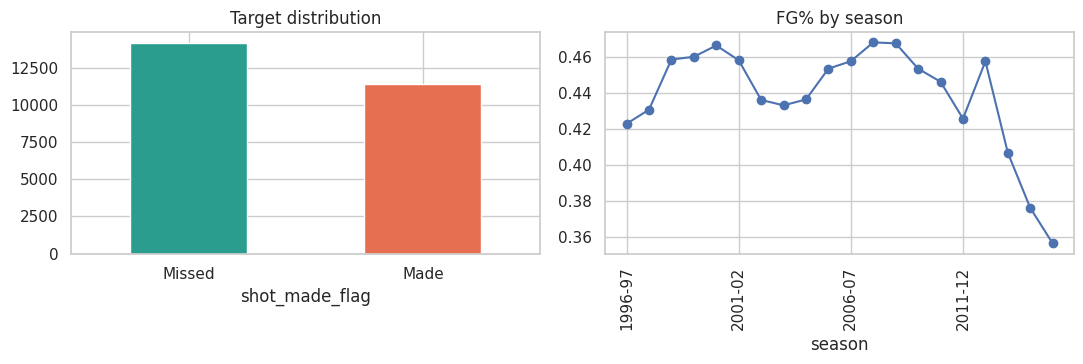

In [9]:
lab = raw[raw["shot_made_flag"].notna()].copy()
lab["shot_made_flag"] = lab["shot_made_flag"].astype(int)

rate = lab["shot_made_flag"].mean()
print(f"Labelled shots: {len(lab)}   Overall field-goal rate: {rate:.3%}")
print("Class balance (made / missed):", lab["shot_made_flag"].value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
lab["shot_made_flag"].map({1: "Made", 0: "Missed"}).value_counts().plot.bar(ax=ax[0], color=["#2a9d8f", "#e76f51"], rot=0)
ax[0].set_title("Target distribution")
lab.groupby("season")["shot_made_flag"].mean().plot(ax=ax[1], marker="o")
ax[1].set_title("FG% by season"); ax[1].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

In [10]:
def rate_table(col, min_n=1):
    t = lab.groupby(col)["shot_made_flag"].agg(attempts="size", fg_pct="mean")
    return t[t.attempts >= min_n].sort_values("fg_pct", ascending=False).round(3)

for col in ["shot_type", "combined_shot_type", "shot_zone_basic", "shot_zone_range", "shot_zone_area", "period", "playoffs"]:
    print(f"--- {col}"); display(rate_table(col))
print("--- action_type (>= 100 attempts)"); display(rate_table("action_type", 100))

--- shot_type


,attempts,fg_pct
shot_type,,
2PT Field Goal,20285,0.477
3PT Field Goal,5412,0.329


--- combined_shot_type


,attempts,fg_pct
combined_shot_type,,
Dunk,1056,0.928
Bank Shot,120,0.792
Layup,4532,0.565
Hook Shot,127,0.535
Jump Shot,19710,0.391
Tip Shot,152,0.349


--- shot_zone_basic


,attempts,fg_pct
shot_zone_basic,,
Restricted Area,5932,0.618
In The Paint (Non-RA),3880,0.454
Mid-Range,10532,0.406
Left Corner 3,240,0.371
Right Corner 3,333,0.339
Above the Break 3,4720,0.329
Backcourt,60,0.017


... (6 outputs left out)

--- playoffs


,attempts,fg_pct
playoffs,,
0,21939,0.446
1,3758,0.445


--- action_type (>= 100 attempts)


,attempts,fg_pct
action_type,,
Slam Dunk Shot,334,0.982
Driving Dunk Shot,257,0.977
Dunk Shot,217,0.779
Jump Bank Shot,289,0.775
Running Jump Shot,779,0.747
Driving Layup Shot,1628,0.741
Pullup Jump shot,402,0.724
Reverse Layup Shot,333,0.637
Step Back Jump shot,106,0.632


In [11]:
# Statistical tests rather than eyeballing charts
ct = pd.crosstab(lab["shot_type"], lab["shot_made_flag"])
chi2, p, _, _ = stats.chi2_contingency(ct)
succ = ct[1].values; nobs = ct.sum(axis=1).values
z, p_z = proportions_ztest(succ, nobs)
print("2PT vs 3PT FG%:", (succ / nobs).round(3), "| chi-square p =", f"{p:.2e}", "| z-test p =", f"{p_z:.2e}")

ct2 = pd.crosstab(lab["playoffs"], lab["shot_made_flag"])
chi2b, p2, _, _ = stats.chi2_contingency(ct2)
print("Playoffs vs regular FG%:", (ct2[1] / ct2.sum(axis=1)).round(3).to_dict(), "| chi-square p =", f"{p2:.3f}")

logit = sm.Logit(lab["shot_made_flag"], sm.add_constant(lab[["shot_distance"]])).fit(disp=0)
print("\nLogit: shot_distance coef =", round(logit.params["shot_distance"], 4),
      "| odds ratio per extra foot =", round(float(np.exp(logit.params["shot_distance"])), 3),
      "| p =", f"{logit.pvalues['shot_distance']:.2e}")

ct3 = pd.crosstab(lab.loc[lab.period <= 4, "period"], lab.loc[lab.period <= 4, "shot_made_flag"])
print("Quarter effect chi-square p =", f"{stats.chi2_contingency(ct3)[1]:.3f}")

2PT vs 3PT FG%: [0.477 0.329] | chi-square p = 2.63e-84 | z-test p = 1.94e-84
Playoffs vs regular FG%: {0: 0.446, 1: 0.445} | chi-square p = 0.854

Logit: shot_distance coef = -0.0441 | odds ratio per extra foot = 0.957 | p = 6.93e-216
Quarter effect chi-square p = 0.000


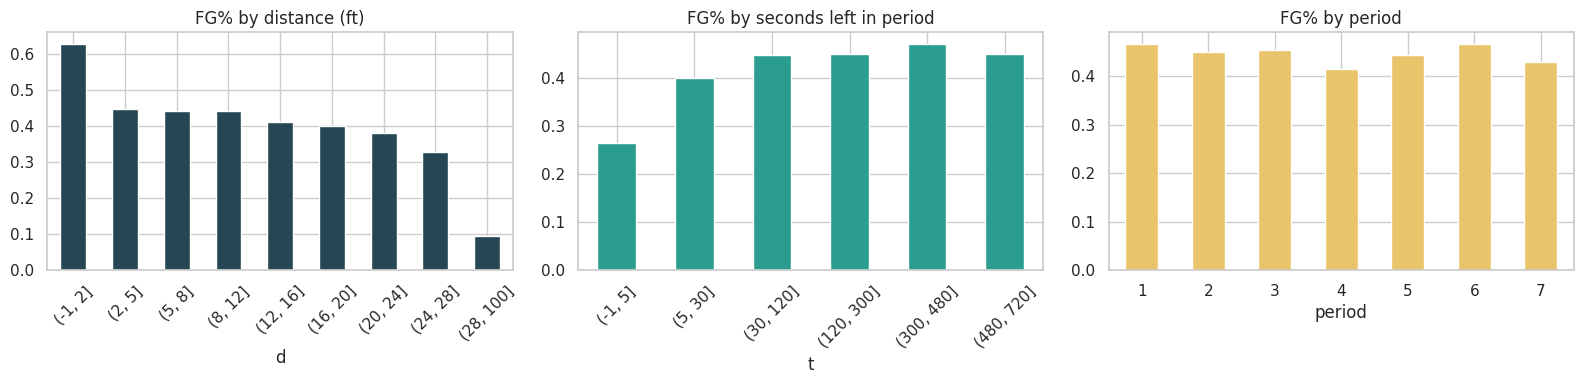

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
lab.assign(d=pd.cut(lab.shot_distance, [-1, 2, 5, 8, 12, 16, 20, 24, 28, 100])).groupby("d")["shot_made_flag"].mean().plot.bar(ax=ax[0], rot=45, color="#264653")
ax[0].set_title("FG% by distance (ft)")
lab.assign(t=pd.cut(lab.minutes_remaining * 60 + lab.seconds_remaining, [-1, 5, 30, 120, 300, 480, 720])).groupby("t")["shot_made_flag"].mean().plot.bar(ax=ax[1], rot=45, color="#2a9d8f")
ax[1].set_title("FG% by seconds left in period")
lab.groupby("period")["shot_made_flag"].agg(["mean", "size"])["mean"].plot.bar(ax=ax[2], rot=0, color="#e9c46a")
ax[2].set_title("FG% by period")
plt.tight_layout(); plt.show()

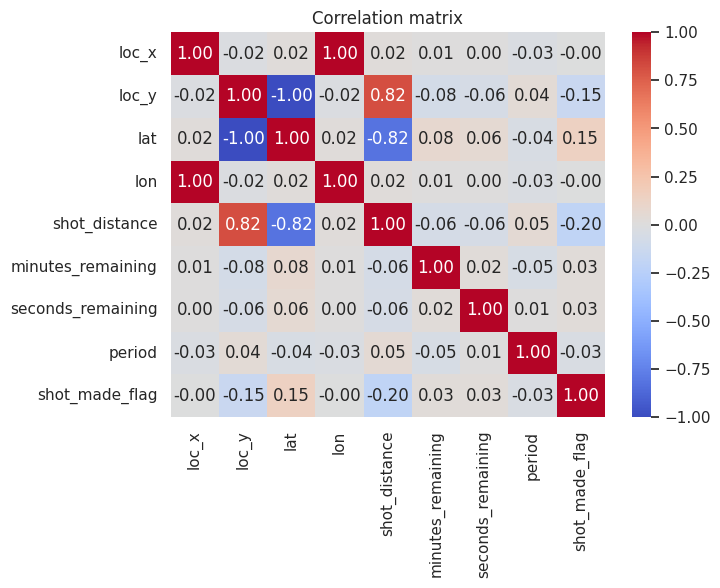

VIF (values > 10 signal strong multicollinearity):
loc_y                271205574.2
loc_x                 21503629.6
lon                    5530558.2
lat                    5096772.9
shot_distance                3.1
minutes_remaining            1.0
seconds_remaining            1.0
period                       1.0


In [13]:
num_eda = ["loc_x", "loc_y", "lat", "lon", "shot_distance", "minutes_remaining", "seconds_remaining", "period"]
plt.figure(figsize=(7, 5))
sns.heatmap(lab[num_eda + ["shot_made_flag"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

X_vif = sm.add_constant(lab[num_eda])
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])], index=num_eda)
print("VIF (values > 10 signal strong multicollinearity):")
print(vif.round(1).sort_values(ascending=False).to_string())

**Findings used downstream.** `lat`/`lon` are linear transforms of `loc_y`/`loc_x` (huge VIF), so they carry no new information and are dropped. `team_id`/`team_name` are constant and are dropped. `game_event_id` and `shot_id` are bookkeeping counters (no causal meaning) and are not used as features. `game_id` is **not** a feature — it is used as the *grouping key* for validation.

## 5. Spatial analysis (court maps)

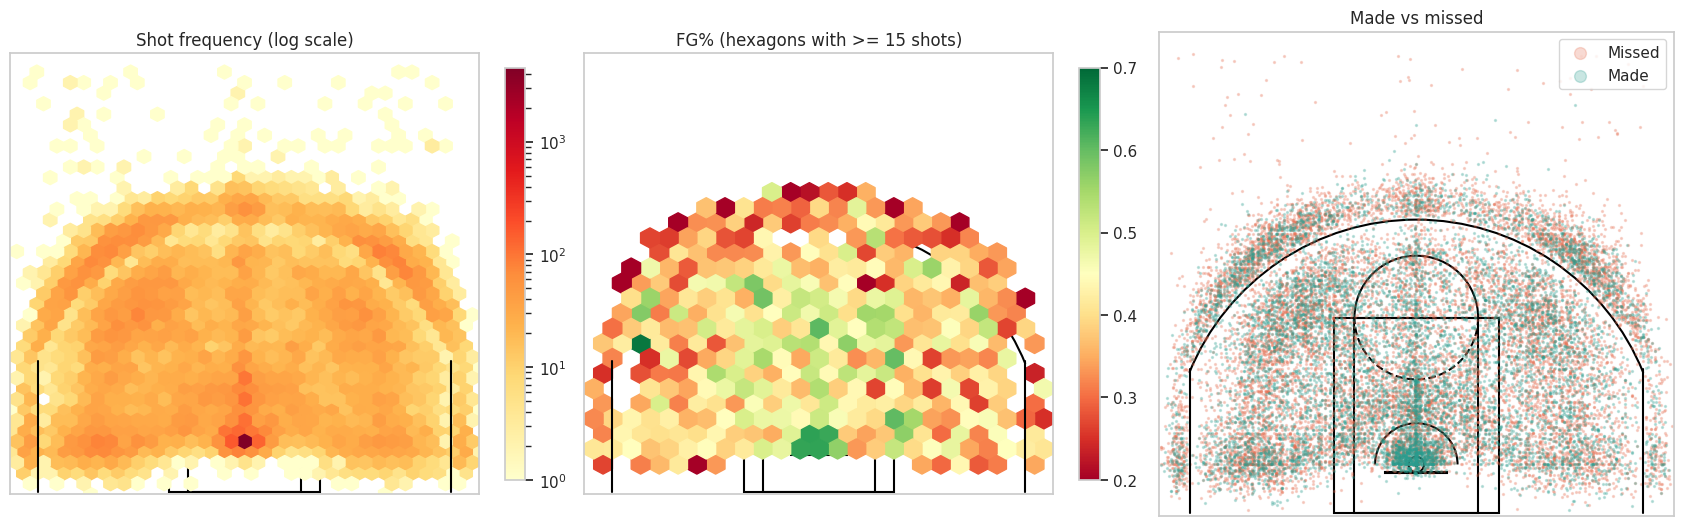

In [14]:
def draw_court(ax=None, color="black", lw=1.5):
    # NBA half court in the dataset's units (tenths of a foot, hoop at (0, 0)).
    ax = ax or plt.gca()
    ax.add_patch(Circle((0, 0), 7.5, lw=lw, color=color, fill=False))
    ax.add_patch(Rectangle((-30, -7.5), 60, -1, lw=lw, color=color))
    ax.add_patch(Rectangle((-80, -47.5), 160, 190, lw=lw, color=color, fill=False))
    ax.add_patch(Rectangle((-60, -47.5), 120, 190, lw=lw, color=color, fill=False))
    ax.add_patch(Arc((0, 142.5), 120, 120, theta1=0, theta2=180, lw=lw, color=color))
    ax.add_patch(Arc((0, 142.5), 120, 120, theta1=180, theta2=0, lw=lw, color=color, ls="dashed"))
    ax.add_patch(Arc((0, 0), 80, 80, theta1=0, theta2=180, lw=lw, color=color))
    ax.plot([-220, -220], [-47.5, 92.5], lw=lw, color=color)
    ax.plot([220, 220], [-47.5, 92.5], lw=lw, color=color)
    ax.add_patch(Arc((0, 0), 475, 475, theta1=22, theta2=158, lw=lw, color=color))
    ax.set_xlim(250, -250); ax.set_ylim(-50, 420); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    return ax

court = lab[(lab.loc_y < 400) & (lab.loc_x.abs() < 250)]
fig, ax = plt.subplots(1, 3, figsize=(17, 6))
for a in ax: draw_court(a)
h1 = ax[0].hexbin(court.loc_x, court.loc_y, gridsize=35, cmap="YlOrRd", mincnt=1, bins="log", extent=(-250, 250, -50, 400))
ax[0].set_title("Shot frequency (log scale)"); plt.colorbar(h1, ax=ax[0], fraction=0.04)
h2 = ax[1].hexbin(court.loc_x, court.loc_y, C=court.shot_made_flag, reduce_C_function=np.mean, gridsize=25,
                  cmap="RdYlGn", mincnt=15, vmin=0.2, vmax=0.7, extent=(-250, 250, -50, 400))
ax[1].set_title("FG% (hexagons with >= 15 shots)"); plt.colorbar(h2, ax=ax[1], fraction=0.04)
ax[2].scatter(court[court.shot_made_flag == 0].loc_x, court[court.shot_made_flag == 0].loc_y, s=2, c="#e76f51", alpha=.25, label="Missed")
ax[2].scatter(court[court.shot_made_flag == 1].loc_x, court[court.shot_made_flag == 1].loc_y, s=2, c="#2a9d8f", alpha=.25, label="Made")
ax[2].legend(markerscale=6); ax[2].set_title("Made vs missed")
plt.tight_layout(); plt.show()

In [15]:
# Validate the coordinate system: is (0,0) the hoop, and are units tenths of feet?
radial_ft = np.hypot(lab.loc_x, lab.loc_y) / 10
print("Correlation(radial distance from (0,0) / 10, shot_distance):", round(np.corrcoef(radial_ft, lab.shot_distance)[0, 1], 4))
print("Median absolute difference (ft):", round(float(np.median(np.abs(radial_ft - lab.shot_distance))), 3))
print("=> loc_x/loc_y are hoop-centred (tenths of ft) and shot_distance is (nearly) redundant with them; "
      "the angle is the genuinely new geometric information.")

Correlation(radial distance from (0,0) / 10, shot_distance): 0.9995
Median absolute difference (ft): 0.396
=> loc_x/loc_y are hoop-centred (tenths of ft) and shot_distance is (nearly) redundant with them; the angle is the genuinely new geometric information.


## 6. Temporal analysis

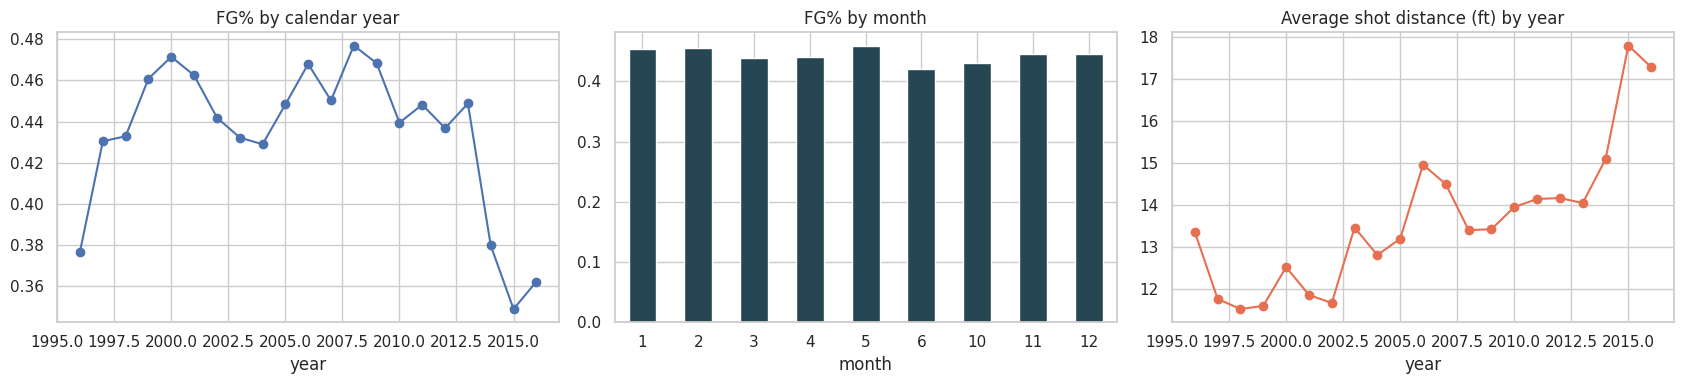

Shots per season:
season
1996-97     383
1997-98     810
1998-99     765
1999-00    1312
2000-01    1575
2001-02    1708
2002-03    1852
2003-04    1371
2004-05    1127
2005-06    1924
2006-07    1579
2007-08    1819
2008-09    1851
2009-10    1772
2010-11    1521
2011-12    1416
2012-13    1328
2013-14      59
2014-15     593
2015-16     932


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
lab.assign(year=lab.game_date.dt.year).groupby("year")["shot_made_flag"].agg(["mean"]).plot(ax=ax[0], marker="o", legend=False)
ax[0].set_title("FG% by calendar year")
lab.assign(month=lab.game_date.dt.month).groupby("month")["shot_made_flag"].mean().plot.bar(ax=ax[1], rot=0, color="#264653")
ax[1].set_title("FG% by month")
lab.assign(year=lab.game_date.dt.year).groupby("year").shot_distance.mean().plot(ax=ax[2], marker="o", color="#e76f51")
ax[2].set_title("Average shot distance (ft) by year")
plt.tight_layout(); plt.show()
print("Shots per season:"); print(lab.groupby("season").size().to_string())

## 7. Feature engineering
Engineered from the circumstances of each shot only (no information about the outcome):

* **Spatial:** shot angle from the hoop, |angle|, distance × |angle| interaction, distance bucket
* **Temporal:** seconds left in period, last-5-seconds, last-minute, overtime flag, game-phase label, season number
* **Context:** home/away (parsed from `matchup`), opponent

> The data has **no shot-clock field**; `last_5s` is the *game clock* in the final 5 s of a period, not a shot-clock proxy.

The feature code is kept in a single source string that is both executed here **and** written to `shot_service.py` in Section 25, so the notebook and the deployed service cannot drift apart. Categorical text is sanitised (no special characters) because XGBoost/LightGBM reject some characters in feature names.

In [17]:
FEATURE_SRC = '''
def sanitize(s):
    return s.astype(str).str.replace(r"[^0-9A-Za-z]+", "_", regex=True).str.strip("_")

def build_features(d):
    f = pd.DataFrame(index=d.index)
    f["loc_x"] = d["loc_x"]; f["loc_y"] = d["loc_y"]
    f["shot_distance"] = d["shot_distance"]
    f["shot_angle"] = np.degrees(np.arctan2(d["loc_x"], d["loc_y"]))
    f["abs_angle"] = f["shot_angle"].abs()
    f["dist_x_angle"] = f["shot_distance"] * f["abs_angle"]
    f["period"] = d["period"]
    f["playoffs"] = d["playoffs"].astype(int)
    f["time_remaining"] = d["minutes_remaining"] * 60 + d["seconds_remaining"]
    f["last_5s"] = (f["time_remaining"] <= 5).astype(int)
    f["last_minute"] = (f["time_remaining"] <= 60).astype(int)
    f["is_overtime"] = (d["period"] > 4).astype(int)
    f["season_num"] = d["season"].astype(str).str[:4].astype(int)
    f["is_home"] = (~d["matchup"].str.contains("@")).astype(int)
    f["dist_bucket"] = pd.cut(d["shot_distance"], [-1, 4, 8, 16, 24, 1000],
                              labels=["0-4", "4-8", "8-16", "16-24", "24+"]).astype(str)
    f["game_phase"] = np.select([d["period"] == 1, d["period"] == 2, d["period"] == 3, d["period"] == 4],
                                ["Q1", "Q2", "Q3", "Q4"], "OT")
    for c in ["action_type", "combined_shot_type", "shot_type", "shot_zone_area",
              "shot_zone_basic", "shot_zone_range", "opponent"]:
        f[c] = d[c]
    cat = ["action_type", "combined_shot_type", "shot_type", "shot_zone_area", "shot_zone_basic",
           "shot_zone_range", "opponent", "dist_bucket", "game_phase"]
    for c in cat:
        f[c] = sanitize(f[c])
    return f
'''
exec(FEATURE_SRC)

CAT = ["action_type", "combined_shot_type", "shot_type", "shot_zone_area", "shot_zone_basic",
       "shot_zone_range", "opponent", "dist_bucket", "game_phase"]
NUM = ["loc_x", "loc_y", "shot_distance", "shot_angle", "abs_angle", "dist_x_angle", "period", "playoffs",
       "time_remaining", "last_5s", "last_minute", "is_overtime", "season_num", "is_home"]

lab = lab.sort_values(["game_date", "game_id", "game_event_id"]).reset_index(drop=True)
FEATS = build_features(lab)[NUM + CAT]
y = lab["shot_made_flag"].values
groups = lab["game_id"].values
print("Feature matrix:", FEATS.shape, "| numeric:", len(NUM), "| categorical:", len(CAT))
FEATS.head()

Feature matrix: (25697, 23) | numeric: 14 | categorical: 9


,loc_x,loc_y,shot_distance,shot_angle,abs_angle,dist_x_angle,period,playoffs,time_remaining,last_5s,last_minute,is_overtime,season_num,is_home,action_type,combined_shot_type,shot_type,shot_zone_area,shot_zone_basic,shot_zone_range,opponent,dist_bucket,game_phase
0,-140,116,18,-50.355825,50.355825,906.404851,1,0,42,0,1,0,1996,1,Jump_Shot,Jump_Shot,2PT_Field_Goal,Left_Side_Center_LC,Mid_Range,16_24_ft,MIN,16_24,Q1
1,-131,97,16,-53.481606,53.481606,855.705693,2,0,608,0,0,0,1996,0,Jump_Shot,Jump_Shot,2PT_Field_Goal,Left_Side_Center_LC,Mid_Range,16_24_ft,NYK,8_16,Q2
2,-142,181,23,-38.115262,38.115262,876.651024,2,0,517,0,0,0,1996,0,Jump_Shot,Jump_Shot,3PT_Field_Goal,Left_Side_Center_LC,Mid_Range,16_24_ft,CHA,16_24,Q2
3,0,0,0,0.000000,0.000000,0.000000,2,0,394,0,0,0,1996,0,Jump_Shot,Jump_Shot,3PT_Field_Goal,Center_C,Restricted_Area,Less_Than_8_ft,CHA,0_4,Q2
4,-10,138,13,-4.144624,4.144624,53.880109,2,0,327,0,0,0,1996,0,Jump_Shot,Jump_Shot,2PT_Field_Goal,Center_C,In_The_Paint_Non_RA,8_16_ft,CHA,8_16,Q2


## 8. Validation design — avoiding leakage
* **Hold-out test set = the most recent ~20 % of games** (chronological). It is **never** used to choose anything.
* **Development set = earlier games.** Model selection uses `StratifiedGroupKFold` (folds never split a game).

First, three evaluation schemes are compared with the same default model, purely to show how much a naive split can flatter the score. (This comparison is informational and drives no decision.)

In [18]:
game_dates = lab.groupby("game_id")["game_date"].min().sort_values()
cutoff_date = game_dates.iloc[int(len(game_dates) * 0.8)]
is_test = (lab["game_date"] >= cutoff_date).values
dev_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]

X_dev, y_dev, g_dev = FEATS.iloc[dev_idx], y[dev_idx], groups[dev_idx]
X_test, y_test, g_test = FEATS.iloc[test_idx], y[test_idx], groups[test_idx]
print(f"Development: {len(X_dev)} shots, {lab.loc[dev_idx,'game_date'].min().date()} -> {lab.loc[dev_idx,'game_date'].max().date()}")
print(f"Hold-out   : {len(X_test)} shots, {lab.loc[test_idx,'game_date'].min().date()} -> {lab.loc[test_idx,'game_date'].max().date()}")
print("FG% dev / test:", round(y_dev.mean(), 3), "/", round(y_test.mean(), 3))
assert set(g_dev).isdisjoint(set(g_test)), "a game appears in both dev and test!"

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(sgkf.split(X_dev, y_dev, g_dev))
FOLDS3 = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(X_dev, y_dev, g_dev))

Development: 20418 shots, 1996-11-03 -> 2011-01-04
Hold-out   : 5279 shots, 2011-01-05 -> 2016-04-13
FG% dev / test: 0.453 / 0.42


In [19]:
def make_pre(scale=False):
    num_t = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), CAT),
        ("num", num_t, NUM)])

def make_pipe(clf, scale=False):
    return Pipeline([("pre", make_pre(scale)), ("clf", clf)])

def evaluate(y_true, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y_true, pred), "f1": f1_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, p), "log_loss": log_loss(y_true, np.clip(p, 1e-6, 1-1e-6)),
            "brier": brier_score_loss(y_true, p)}

def lgbm_default():
    return LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=31, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=SEED, verbosity=-1, n_jobs=-1)

res = {}
tr, te = train_test_split(np.arange(len(FEATS)), test_size=0.2, stratify=y, random_state=SEED)
gss = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(FEATS, y, groups))
for name, (a, b) in {"A: random split": (tr, te), "B: group split (unseen games)": gss,
                     "C: chronological (future games)": (dev_idx, test_idx)}.items():
    m = make_pipe(lgbm_default()).fit(FEATS.iloc[a], y[a])
    res[name] = evaluate(y[b], m.predict_proba(FEATS.iloc[b])[:, 1])
display(pd.DataFrame(res).T[["accuracy", "f1", "roc_auc", "log_loss"]].round(4))

,accuracy,f1,roc_auc,log_loss
A: random split,0.6901,0.5668,0.7154,0.5941
B: group split (unseen games),0.6883,0.5630,0.7068,0.5987
C: chronological (future games),0.6746,0.5615,0.6960,0.6157


Scheme **C** is the honest estimate of production performance (predicting later games). Differences between A, B and C quantify how much optimism a naive split adds.

## 9. Model comparison — seven algorithms (grouped 5-fold CV on development data)
Hold-out predictions are stored so the final report can show them side by side, but they are **not** used for any selection.

In [20]:
pos_w = float((y_dev == 0).sum() / (y_dev == 1).sum())   # close to 1, i.e. classes are only mildly imbalanced
print("Class ratio (neg/pos) in dev:", round(pos_w, 3))

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000, C=1.0), scale=True),
    "Random Forest": make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
    "Extra Trees": make_pipe(ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
    "HistGradientBoosting": make_pipe(HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=SEED)),
    "XGBoost": make_pipe(XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                       eval_metric="logloss", random_state=SEED, n_jobs=-1)),
    "LightGBM": make_pipe(lgbm_default()),
    "CatBoost": make_pipe(CatBoostClassifier(iterations=CAT_ITERS, learning_rate=0.05, depth=6, verbose=0,
                                             random_seed=SEED, thread_count=-1)),
}

def oof_proba(pipe, folds=FOLDS):
    oof = np.zeros(len(X_dev))
    for tr_i, va_i in folds:
        m = clone(pipe).fit(X_dev.iloc[tr_i], y_dev[tr_i])
        oof[va_i] = m.predict_proba(X_dev.iloc[va_i])[:, 1]
    return oof

OOF, TEST_P, FITTED, rows = {}, {}, {}, []
for name, pipe in models.items():
    t0 = time.time()
    OOF[name] = oof_proba(pipe)
    FITTED[name] = clone(pipe).fit(X_dev, y_dev)
    TEST_P[name] = FITTED[name].predict_proba(X_test)[:, 1]
    cv_m = evaluate(y_dev, OOF[name])
    rows.append({"model": name, **{f"cv_{k}": v for k, v in cv_m.items() if k in ["accuracy", "f1", "roc_auc", "log_loss"]},
                 "seconds": round(time.time() - t0, 1)})
    print(f"{name:22s} done in {time.time()-t0:5.1f}s")

baseline_table = pd.DataFrame(rows).set_index("model").round(4).sort_values("cv_log_loss")
display(baseline_table)

Class ratio (neg/pos) in dev: 1.208
Logistic Regression    done in  12.9s
Random Forest          done in  44.3s
Extra Trees            done in  35.3s
HistGradientBoosting   done in  10.9s
XGBoost                done in   7.7s
LightGBM               done in   7.9s
CatBoost               done in  19.2s


,cv_accuracy,cv_f1,cv_roc_auc,cv_log_loss,seconds
model,,,,,
HistGradientBoosting,0.6842,0.5646,0.7105,0.6001,10.9
LightGBM,0.6838,0.5671,0.7095,0.6003,7.9
CatBoost,0.6850,0.5679,0.7084,0.6005,19.2
XGBoost,0.6848,0.5701,0.7086,0.6007,7.7
Extra Trees,0.6834,0.5687,0.7080,0.6018,35.3
Random Forest,0.6846,0.5724,0.7069,0.6031,44.3
Logistic Regression,0.6835,0.5648,0.6987,0.6067,12.9


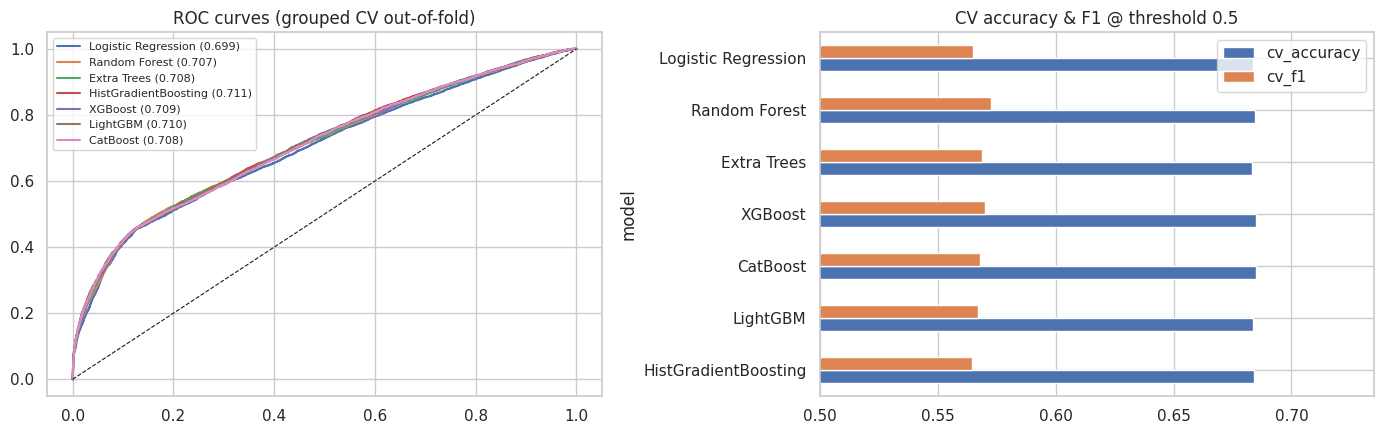

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name in OOF:
    fpr, tpr, _ = roc_curve(y_dev, OOF[name]); ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_dev, OOF[name]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_title("ROC curves (grouped CV out-of-fold)"); ax[0].legend(fontsize=8)
baseline_table[["cv_accuracy", "cv_f1"]].plot.barh(ax=ax[1]); ax[1].set_xlim(0.5, baseline_table[["cv_accuracy", "cv_f1"]].max().max() + .05)
ax[1].set_title("CV accuracy & F1 @ threshold 0.5")
plt.tight_layout(); plt.show()

## 10. Hyper-parameter optimisation (Optuna, Bayesian/TPE)
XGBoost and LightGBM are tuned with the objective **mean log-loss over grouped 3-fold CV inside the development set**; the hold-out is never used. Log-loss is optimised during tuning because it is smooth and stable (accuracy/F1 are step functions that make the search noisy). The *model-selection* decision itself uses the accuracy/F1-based score (Section 12), and the decision threshold is tuned afterwards (Section 14).

In [22]:
def cv_logloss(make_model, params, folds=FOLDS3):
    scores = []
    for tr_i, va_i in folds:
        m = make_pipe(make_model(params)).fit(X_dev.iloc[tr_i], y_dev[tr_i])
        scores.append(log_loss(y_dev[va_i], m.predict_proba(X_dev.iloc[va_i])[:, 1]))
    return float(np.mean(scores))

def make_xgb(p):
    return XGBClassifier(**p, eval_metric="logloss", random_state=SEED, n_jobs=-1)

def make_lgb(p):
    return LGBMClassifier(**p, subsample_freq=1, random_state=SEED, verbosity=-1, n_jobs=-1)

def space_xgb(t):
    return dict(n_estimators=t.suggest_int("n_estimators", 100, 600),
                max_depth=t.suggest_int("max_depth", 2, 8),
                learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                min_child_weight=t.suggest_int("min_child_weight", 1, 30),
                subsample=t.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
                reg_lambda=t.suggest_float("reg_lambda", 1e-2, 20, log=True),
                reg_alpha=t.suggest_float("reg_alpha", 1e-3, 5, log=True))

def space_lgb(t):
    return dict(n_estimators=t.suggest_int("n_estimators", 100, 600),
                num_leaves=t.suggest_int("num_leaves", 8, 96),
                learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                min_child_samples=t.suggest_int("min_child_samples", 10, 150),
                subsample=t.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
                reg_lambda=t.suggest_float("reg_lambda", 1e-2, 20, log=True),
                reg_alpha=t.suggest_float("reg_alpha", 1e-3, 5, log=True))

STUDIES = {}
for label, mk, sp in [("XGBoost", make_xgb, space_xgb), ("LightGBM", make_lgb, space_lgb)]:
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(lambda t, mk=mk, sp=sp: cv_logloss(mk, sp(t)), n_trials=N_TRIALS)
    STUDIES[label] = (study, mk)
    print(f"{label}: best 3-fold CV log-loss {study.best_value:.4f}")
    print("   best params:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in study.best_params.items()})

XGBoost: best 3-fold CV log-loss 0.6013
   best params: {'n_estimators': 263, 'max_depth': 8, 'learning_rate': 0.015, 'min_child_weight': 12, 'subsample': 0.9633, 'colsample_bytree': 0.5666, 'reg_lambda': 0.0419, 'reg_alpha': 0.0104}
LightGBM: best 3-fold CV log-loss 0.6025
   best params: {'n_estimators': 403, 'num_leaves': 26, 'learning_rate': 0.0101, 'min_child_samples': 68, 'subsample': 0.7434, 'colsample_bytree': 0.9058, 'reg_lambda': 5.8703, 'reg_alpha': 0.0116}


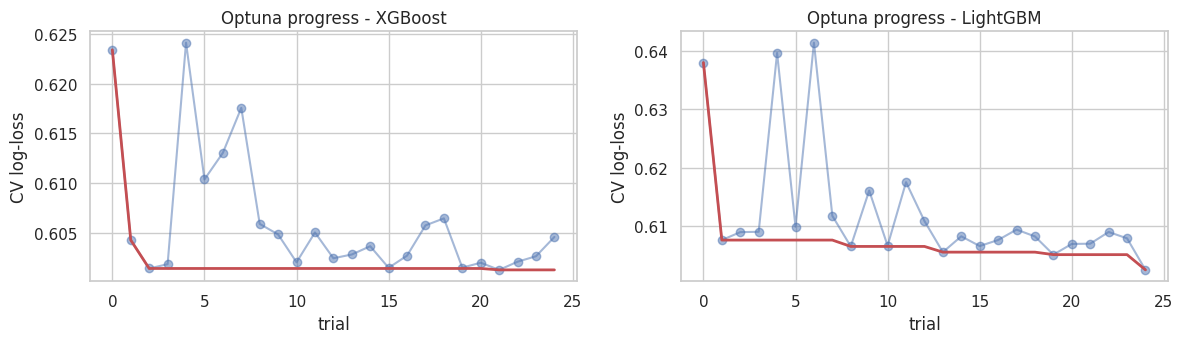

Tuned XGBoost    5-fold CV log-loss 0.6006  acc@0.5 0.6836
Tuned LightGBM   5-fold CV log-loss 0.6014  acc@0.5 0.6845
Note: the tuned parameters were chosen using these same development folds, so their CV scores are slightly optimistic; Section 21 (nested CV) measures how much.


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, (label, (study, _)) in zip(ax, STUDIES.items()):
    vals = [t.value for t in study.trials]
    a.plot(vals, "o-", alpha=.5); a.plot(np.minimum.accumulate(vals), "r-", lw=2)
    a.set_title(f"Optuna progress - {label}"); a.set_xlabel("trial"); a.set_ylabel("CV log-loss")
plt.tight_layout(); plt.show()

TUNED = {f"Tuned {k}": make_pipe(mk(study.best_params)) for k, (study, mk) in STUDIES.items()}
for name, pipe in TUNED.items():
    OOF[name] = oof_proba(pipe)
    FITTED[name] = clone(pipe).fit(X_dev, y_dev)
    TEST_P[name] = FITTED[name].predict_proba(X_test)[:, 1]
    print(f"{name:16s} 5-fold CV log-loss {log_loss(y_dev, OOF[name]):.4f}  acc@0.5 {accuracy_score(y_dev, OOF[name] >= .5):.4f}")
print("Note: the tuned parameters were chosen using these same development folds, so their CV scores are slightly optimistic; "
      "Section 21 (nested CV) measures how much.")

## 11. Ensembles — soft voting and *nested* group-aware stacking
* **Soft voting** – mean probability of tuned XGBoost, tuned LightGBM and CatBoost. It has no trainable combiner, so it needs no extra validation.
* **Stacking with nested cross-fitting.** A naive stack trains the meta-model on out-of-fold base predictions and then cross-validates it using the *same* base predictions. Those predictions were produced by base models that had seen the meta-validation fold, which leaks information. Here, for every outer fold:
  1. the base models' predictions for the **outer training games only** are rebuilt with an *inner* grouped cross-fit;
  2. the meta-model is trained on those inner predictions;
  3. the outer validation fold is scored using base models trained on the outer training games (never on the validation games).

  The resulting out-of-fold predictions are therefore honest. For the hold-out/production model, the meta-model is fitted on all development out-of-fold base predictions (standard practice); its *validation estimate* is the nested one.

In [24]:
PREDICT_SRC = '''
REQUIRED_COLUMNS = ["action_type", "combined_shot_type", "loc_x", "loc_y", "shot_distance", "period", "playoffs",
                    "minutes_remaining", "seconds_remaining", "season", "matchup", "opponent", "shot_type",
                    "shot_zone_area", "shot_zone_basic", "shot_zone_range"]

def logit_feat(m):
    m = np.clip(np.asarray(m, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(m / (1 - m))

def apply_calibrator(cal, q):
    q = np.asarray(q, dtype=float)
    if cal is None or cal["method"] == "none":
        return q
    if cal["method"] == "platt":
        return cal["model"].predict_proba(logit_feat(q).reshape(-1, 1))[:, 1]
    return cal["model"].predict(q)

def predict_artifact(art, X):
    P = np.column_stack([m.predict_proba(X)[:, 1] for m in art["models"].values()])
    if art["mode"] == "stack":
        p = art["meta"].predict_proba(logit_feat(P))[:, 1]
    else:
        p = P.mean(axis=1)
    return apply_calibrator(art.get("calibrator"), p)

def predict_shot_row(art, row):
    missing = [c for c in REQUIRED_COLUMNS if c not in row]
    if missing:
        raise ValueError("Missing required fields: " + ", ".join(missing))
    d = pd.DataFrame([row])
    f = build_features(d)[art["num_features"] + art["cat_features"]]
    p = float(predict_artifact(art, f)[0])
    return {"probability_of_scoring": round(p, 3),
            "predicted": "MADE" if p >= art["threshold"] else "MISSED",
            "threshold": round(float(art["threshold"]), 3),
            "model": art["name"]}
'''
exec(PREDICT_SRC)

def fit_predict_pipe(pipe, Xa, ya, Xb):
    return clone(pipe).fit(Xa, ya).predict_proba(Xb)[:, 1]

SINGLE = {**models, **TUNED}
base_names = ["Tuned XGBoost", "Tuned LightGBM", "CatBoost"]
oof_mat = np.column_stack([OOF[n] for n in base_names])
test_mat = np.column_stack([TEST_P[n] for n in base_names])

OOF["Soft Voting"] = oof_mat.mean(axis=1)
TEST_P["Soft Voting"] = test_mat.mean(axis=1)

def stack_nested_oof(base_pipes, base_oof, inner_splits=3):
    # Honest out-of-fold predictions of a stacked model via nested, group-aware cross-fitting.
    out = np.zeros(len(X_dev))
    for tr_i, va_i in FOLDS:
        Xtr, ytr, gtr = X_dev.iloc[tr_i], y_dev[tr_i], g_dev[tr_i]
        inner = list(StratifiedGroupKFold(n_splits=inner_splits, shuffle=True, random_state=SEED).split(Xtr, ytr, gtr))
        inner_oof = np.zeros((len(tr_i), len(base_pipes)))
        for j, pipe in enumerate(base_pipes):
            for a, b in inner:
                inner_oof[b, j] = fit_predict_pipe(pipe, Xtr.iloc[a], ytr[a], Xtr.iloc[b])
        meta = LogisticRegression(C=1.0).fit(logit_feat(inner_oof), ytr)
        # base_oof[va_i] came from base models fitted on exactly tr_i (the same outer fold), so it is reused here
        out[va_i] = meta.predict_proba(logit_feat(base_oof[va_i]))[:, 1]
    return out

t0 = time.time()
OOF["Stacking (nested)"] = stack_nested_oof([SINGLE[n] for n in base_names], oof_mat)
meta_model = LogisticRegression(C=1.0).fit(logit_feat(oof_mat), y_dev)
TEST_P["Stacking (nested)"] = meta_model.predict_proba(logit_feat(test_mat))[:, 1]
print(f"Nested stacking validated in {time.time()-t0:.0f}s | meta-weights on logit(prob):",
      {k: round(float(v), 3) for k, v in zip(base_names, meta_model.coef_[0])})

cmp = pd.DataFrame({n: evaluate(y_dev, OOF[n]) for n in base_names + ["Soft Voting", "Stacking (nested)"]}).T
display(cmp[["accuracy", "f1", "roc_auc", "log_loss", "brier"]].round(4))
print("Ensembles are kept only if they win the predefined selection rule in Section 12.")

Nested stacking validated in 84s | meta-weights on logit(prob): {'Tuned XGBoost': 0.508, 'Tuned LightGBM': 0.089, 'CatBoost': 0.465}


,accuracy,f1,roc_auc,log_loss,brier
Tuned XGBoost,0.6836,0.5670,0.7109,0.6006,0.2075
Tuned LightGBM,0.6845,0.5667,0.7100,0.6014,0.2078
CatBoost,0.6850,0.5679,0.7084,0.6005,0.2076
Soft Voting,0.6850,0.5678,0.7112,0.5996,0.2071
Stacking (nested),0.6853,0.5687,0.7114,0.5992,0.2070


Ensembles are kept only if they win the predefined selection rule in Section 12.


## 12. Model selection — predefined, assignment-aligned rule
**SelectionScore = (Accuracy + F1) / 2**, computed on the development-set out-of-fold predictions at each model's own out-of-fold-optimal threshold (searched on 0.30 – 0.70).

Rule (fixed *before* looking at results):
1. Rank every candidate by SelectionScore.
2. Candidates within **0.003** of the best score are treated as tied (that gap is smaller than fold-to-fold noise).
3. Among tied candidates, pick the **lowest log-loss** (ROC-AUC and log-loss are reported as additional criteria).

In [25]:
GRID = np.linspace(0.30, 0.70, 81)

def sel_score(y_true, p, thr):
    pr = (p >= thr).astype(int)
    return (accuracy_score(y_true, pr) + f1_score(y_true, pr)) / 2

def best_threshold(y_true, p):
    sc = np.array([sel_score(y_true, p, t) for t in GRID])
    i = int(sc.argmax())
    return float(GRID[i]), float(sc[i])

cand_all = list(models) + ["Tuned XGBoost", "Tuned LightGBM", "Soft Voting", "Stacking (nested)"]
rows = []
for n in cand_all:
    thr, sc = best_threshold(y_dev, OOF[n])
    e = evaluate(y_dev, OOF[n], thr)
    rows.append({"model": n, "threshold": thr, "selection_score": sc, "accuracy": e["accuracy"], "f1": e["f1"],
                 "roc_auc": e["roc_auc"], "log_loss": e["log_loss"], "score_at_0.5": sel_score(y_dev, OOF[n], 0.5)})
sel_raw = pd.DataFrame(rows).set_index("model").sort_values("selection_score", ascending=False)
TIE = 0.003
top_score = sel_raw["selection_score"].max()
contenders = sel_raw[sel_raw["selection_score"] >= top_score - TIE]
BEST_NAME = contenders["log_loss"].idxmin()
sel = sel_raw.round(4)
display(sel)
print(f"Best SelectionScore: {top_score:.4f} | tied contenders (within {TIE}): {list(contenders.index)}")
print("SELECTED ->", BEST_NAME)

,threshold,selection_score,accuracy,f1,roc_auc,log_loss,score_at_0.5
model,,,,,,,
Extra Trees,0.420,0.6350,0.6672,0.6029,0.7080,0.6018,0.6261
Random Forest,0.445,0.6349,0.6764,0.5934,0.7069,0.6031,0.6285
Tuned XGBoost,0.400,0.6330,0.6569,0.6090,0.7109,0.6006,0.6253
HistGradientBoosting,0.385,0.6326,0.6450,0.6202,0.7105,0.6001,0.6244
LightGBM,0.420,0.6321,0.6635,0.6008,0.7095,0.6003,0.6254
Stacking (nested),0.410,0.6320,0.6647,0.5993,0.7114,0.5992,0.6270
Soft Voting,0.400,0.6313,0.6550,0.6075,0.7112,0.5996,0.6264
Tuned LightGBM,0.410,0.6309,0.6622,0.5997,0.7100,0.6014,0.6256
CatBoost,0.435,0.6305,0.6750,0.5860,0.7084,0.6005,0.6265


Best SelectionScore: 0.6350 | tied contenders (within 0.003): ['Extra Trees', 'Random Forest', 'Tuned XGBoost', 'HistGradientBoosting', 'LightGBM']
SELECTED -> HistGradientBoosting


## 13. Probability calibration — method chosen by development-set cross-validation
Platt scaling (sigmoid) and isotonic regression are compared with *no calibration* by **cross-fitting on the development out-of-fold predictions** (a calibrator is fitted on the training folds' predictions and applied to the validation fold). The hold-out plays **no part** in this choice. Rule: pick the method with the lowest CV Brier score; adopt calibration only if it beats "none" by at least 0.0003 Brier.

,brier,log_loss,ece
none,0.20733,0.60012,0.01118
platt,0.20735,0.60015,0.00925
isotonic,0.20748,0.60421,0.00431


Calibration method selected on development CV: none


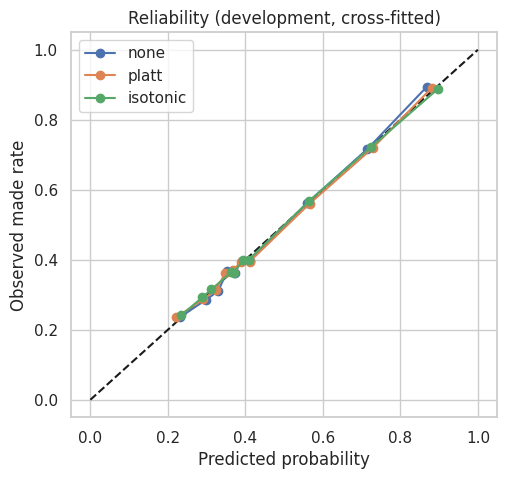

In [26]:
def fit_calibrator(method, p, yv):
    if method == "none":
        return {"method": "none", "model": None}
    if method == "platt":
        return {"method": "platt", "model": LogisticRegression(C=1e6).fit(logit_feat(p).reshape(-1, 1), yv)}
    return {"method": "isotonic", "model": IsotonicRegression(out_of_bounds="clip").fit(p, yv)}

def cv_calibrate(method, p):
    out = np.zeros(len(p))
    for tr_i, va_i in FOLDS:
        out[va_i] = apply_calibrator(fit_calibrator(method, p[tr_i], y_dev[tr_i]), p[va_i])
    return out

def ece(y_true, p, bins=10):
    y_true, p = np.asarray(y_true), np.asarray(p)
    edges = np.quantile(p, np.linspace(0, 1, bins + 1))
    idx = np.clip(np.searchsorted(edges[1:-1], p, side="right"), 0, bins - 1)
    tot = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            tot += m.mean() * abs(p[m].mean() - y_true[m].mean())
    return float(tot)

p_oof = OOF[BEST_NAME]
CAL_OOF = {m: cv_calibrate(m, p_oof) for m in ["none", "platt", "isotonic"]}
cal_table = pd.DataFrame({m: {"brier": brier_score_loss(y_dev, v), "log_loss": log_loss(y_dev, np.clip(v, 1e-6, 1 - 1e-6)),
                              "ece": ece(y_dev, v)} for m, v in CAL_OOF.items()}).T
display(cal_table.round(5))

best_cal = cal_table["brier"].idxmin()
CAL_METHOD = best_cal if (cal_table.loc["none", "brier"] - cal_table.loc[best_cal, "brier"]) >= 0.0003 else "none"
print("Calibration method selected on development CV:", CAL_METHOD)
cal_final = fit_calibrator(CAL_METHOD, p_oof, y_dev)

plt.figure(figsize=(5.5, 5)); plt.plot([0, 1], [0, 1], "k--")
for k, v in CAL_OOF.items():
    fy, fx = calibration_curve(y_dev, v, n_bins=10, strategy="quantile"); plt.plot(fx, fy, "o-", label=k)
plt.xlabel("Predicted probability"); plt.ylabel("Observed made rate"); plt.title("Reliability (development, cross-fitted)"); plt.legend(); plt.show()

## 14. Decision-threshold optimisation
The threshold maximises the SelectionScore on the development out-of-fold probabilities **after** the chosen calibration (never on the hold-out). Optimising the F1 of the 'made' class alone can be gamed by predicting everything as made, which is why the mean of accuracy and F1 is used.

Chosen threshold: 0.385  (dev out-of-fold SelectionScore 0.6326; at 0.5: 0.6244)


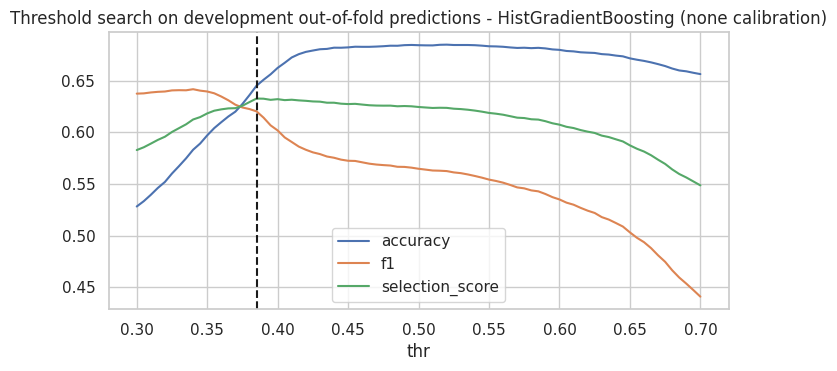

In [27]:
cal_oof_final = CAL_OOF[CAL_METHOD]
THR, thr_score = best_threshold(y_dev, cal_oof_final)
print(f"Chosen threshold: {THR:.3f}  (dev out-of-fold SelectionScore {thr_score:.4f}; at 0.5: {sel_score(y_dev, cal_oof_final, 0.5):.4f})")
curve = pd.DataFrame({"thr": GRID,
                      "accuracy": [accuracy_score(y_dev, cal_oof_final >= t) for t in GRID],
                      "f1": [f1_score(y_dev, cal_oof_final >= t) for t in GRID]})
curve["selection_score"] = (curve.accuracy + curve.f1) / 2
curve.set_index("thr")[["accuracy", "f1", "selection_score"]].plot(figsize=(8, 3.6)); plt.axvline(THR, color="k", ls="--")
plt.title(f"Threshold search on development out-of-fold predictions - {BEST_NAME} ({CAL_METHOD} calibration)"); plt.show()

## 15. Final evaluation on the chronological hold-out
Every decision (model, calibration, threshold) was fixed in Sections 12 – 14 using development data only. This is the first time the selected configuration meets the hold-out.

In [28]:
final_raw = TEST_P[BEST_NAME]
final_p = apply_calibrator(cal_final, final_raw)
final_default = evaluate(y_test, final_p, 0.5)
final_tuned = evaluate(y_test, final_p, THR)
display(pd.DataFrame({"threshold 0.5": final_default, f"threshold {THR:.2f} (from dev CV)": final_tuned}).T.round(4))

maj = max(y_test.mean(), 1 - y_test.mean())
print(f"Majority-class accuracy on hold-out: {maj:.4f}")

rng = np.random.default_rng(SEED)
by_game = pd.Series(np.arange(len(y_test))).groupby(g_test).indices
keys = np.array(list(by_game.keys()))
boot = []
for _ in range(N_BOOT):
    pick = rng.choice(keys, size=len(keys), replace=True)
    idx = np.concatenate([by_game[k] for k in pick])
    if len(np.unique(y_test[idx])) < 2: continue
    e = evaluate(y_test[idx], final_p[idx], THR); boot.append([e["accuracy"], e["f1"], e["roc_auc"]])
boot = np.array(boot)
ci = pd.DataFrame(np.percentile(boot, [2.5, 50, 97.5], axis=0).T, index=["accuracy", "f1", "roc_auc"], columns=["2.5%", "median", "97.5%"]).round(4)
print(f"95% game-level bootstrap CI ({len(boot)} resamples):"); display(ci)

,accuracy,f1,precision,recall,roc_auc,log_loss,brier
threshold 0.5,0.6736,0.5626,0.6438,0.4995,0.6947,0.6176,0.2146
threshold 0.39 (from dev CV),0.6139,0.6021,0.5310,0.6952,0.6947,0.6176,0.2146


Majority-class accuracy on hold-out: 0.5798
95% game-level bootstrap CI (500 resamples):


,2.5%,median,97.5%
accuracy,0.5993,0.6139,0.6306
f1,0.5847,0.6028,0.6190
roc_auc,0.6786,0.6950,0.7113


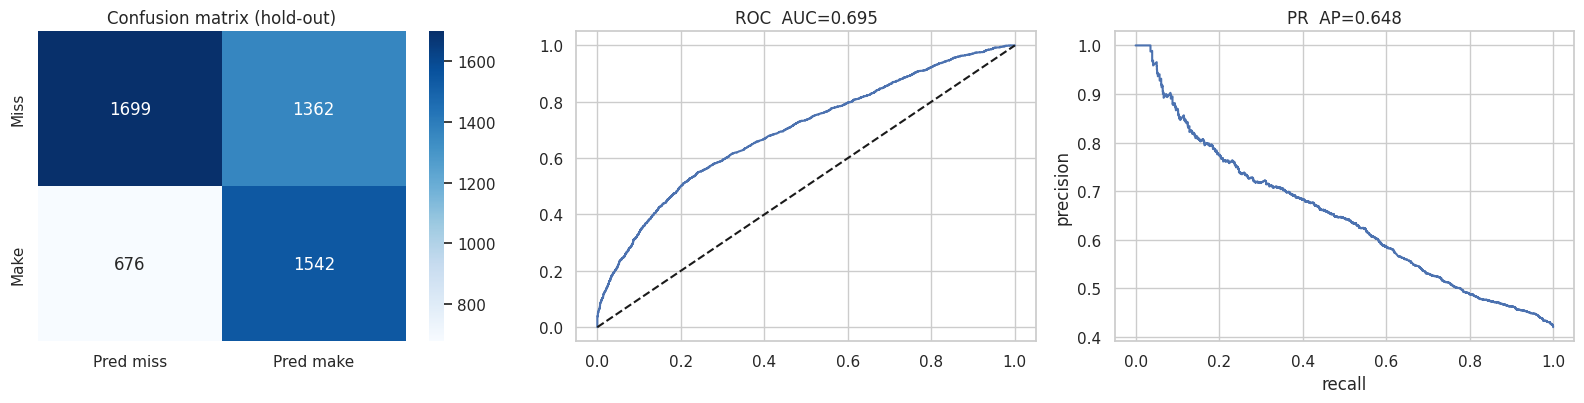

In [29]:
pred_te = (final_p >= THR).astype(int)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.heatmap(confusion_matrix(y_test, pred_te), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Pred miss", "Pred make"], yticklabels=["Miss", "Make"]); ax[0].set_title("Confusion matrix (hold-out)")
fpr, tpr, _ = roc_curve(y_test, final_p); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title(f"ROC  AUC={roc_auc_score(y_test, final_p):.3f}")
pr, rc, _ = precision_recall_curve(y_test, final_p); ax[2].plot(rc, pr); ax[2].set_title(f"PR  AP={average_precision_score(y_test, final_p):.3f}")
ax[2].set_xlabel("recall"); ax[2].set_ylabel("precision")
plt.tight_layout(); plt.show()

## 16. Explainable AI — SHAP, permutation importance, feature interactions and a stakeholder explainability report
SHAP uses the tuned XGBoost/LightGBM with the lower CV log-loss, because `TreeExplainer` needs a single tree model. It explains what the model *uses*, not what *causes* a make. This section drives no selection.

Explaining: Tuned XGBoost | SHAP matrix: (2000, 112)


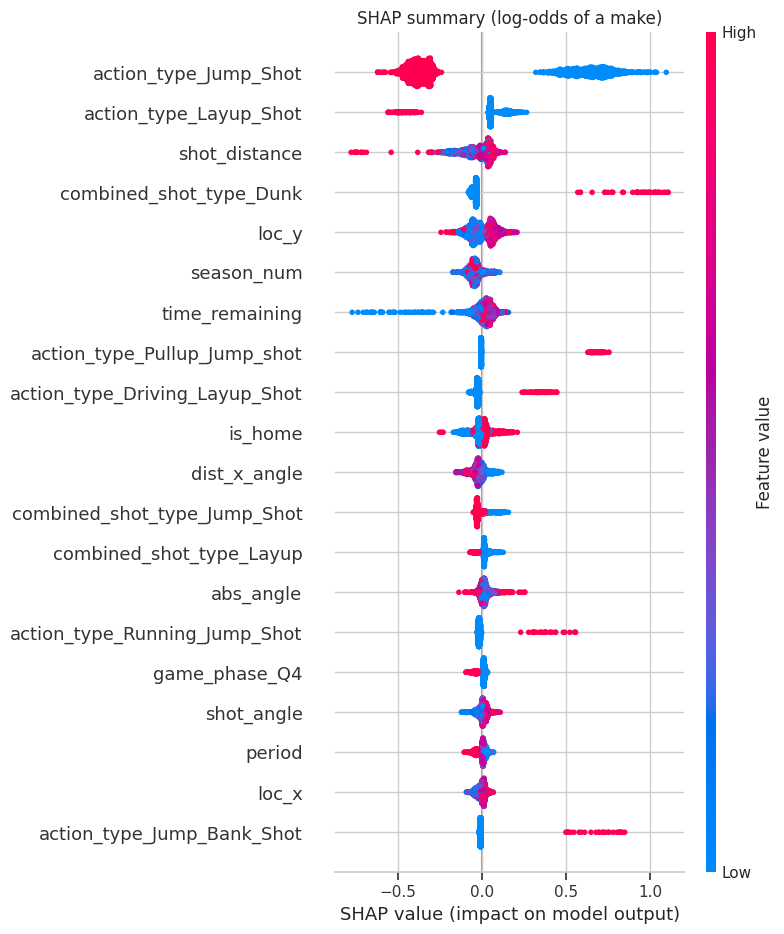

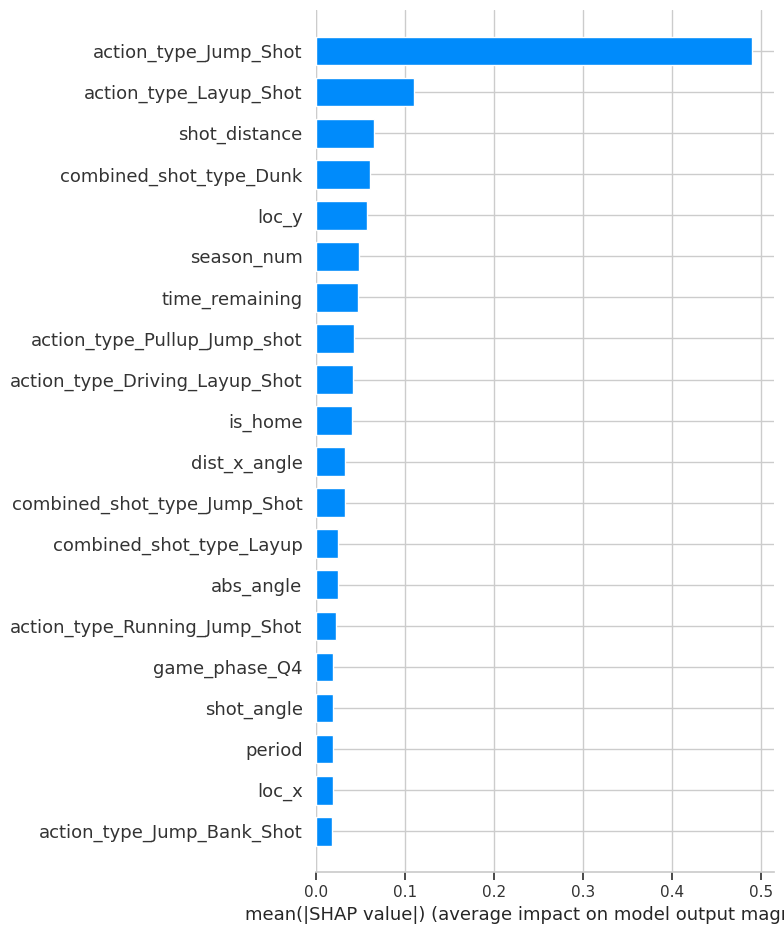

In [30]:
single_name = min(["Tuned XGBoost", "Tuned LightGBM"], key=lambda n: log_loss(y_dev, OOF[n]))
pipe_shap = FITTED[single_name]
pre, clf = pipe_shap.named_steps["pre"], pipe_shap.named_steps["clf"]
feat_names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]

samp = X_test.sample(min(2000, len(X_test)), random_state=SEED)
Xt = pre.transform(samp)
explainer = shap.TreeExplainer(clf)
sv = explainer.shap_values(Xt)
if isinstance(sv, list): sv = sv[-1]
sv = np.asarray(sv)
if sv.ndim == 3: sv = sv[:, :, -1]
base_val = float(np.ravel(explainer.expected_value)[-1])
print("Explaining:", single_name, "| SHAP matrix:", sv.shape)

plt.figure(); shap.summary_plot(sv, Xt, feature_names=feat_names, max_display=20, show=False); plt.title("SHAP summary (log-odds of a make)"); plt.tight_layout(); plt.show()
plt.figure(); shap.summary_plot(sv, Xt, feature_names=feat_names, plot_type="bar", max_display=20, show=False); plt.tight_layout(); plt.show()

<Figure size 600x400 with 0 Axes>

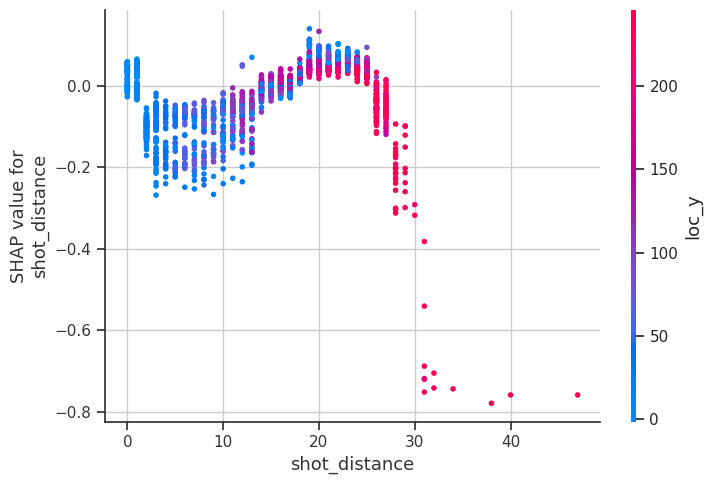

<Figure size 600x400 with 0 Axes>

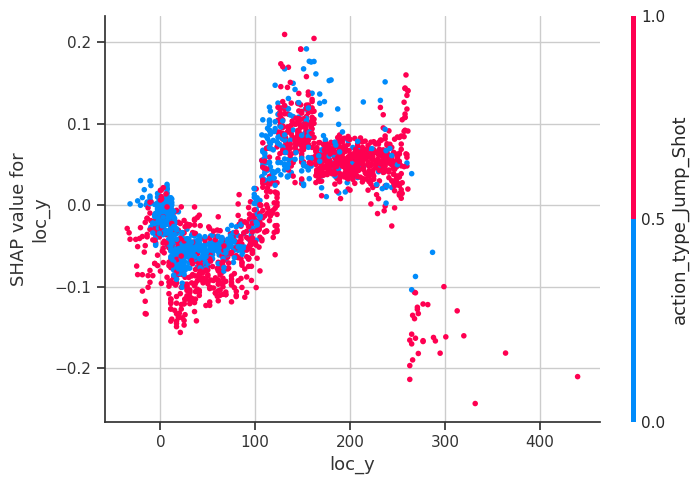

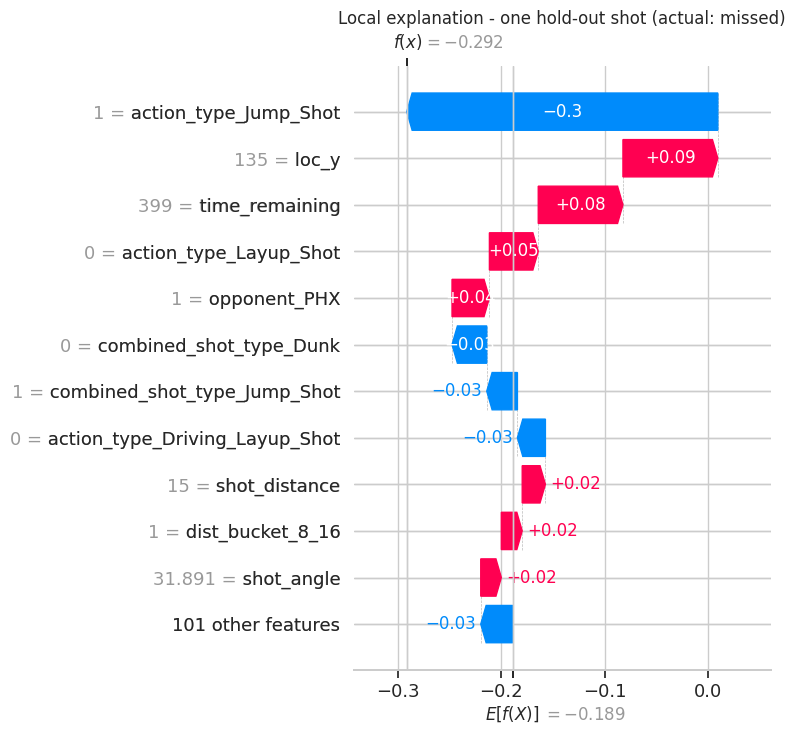

In [31]:
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=feat_names).sort_values(ascending=False)
num_top = [f for f in mean_abs.index if f in NUM][:2]
for f in num_top:
    plt.figure(figsize=(6, 4)); shap.dependence_plot(f, sv, Xt, feature_names=feat_names, show=False); plt.tight_layout(); plt.show()

i = 0
actual_i = y_test[X_test.index.get_indexer(samp.index)[i]]
expl = shap.Explanation(values=sv[i], base_values=base_val, data=Xt[i], feature_names=feat_names)
shap.plots.waterfall(expl, max_display=12, show=False)
plt.title("Local explanation - one hold-out shot (actual: " + ("made" if actual_i else "missed") + ")"); plt.tight_layout(); plt.show()

In [32]:
pi = permutation_importance(pipe_shap, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=1)
pi_df = pd.DataFrame({"feature": X_test.columns, "auc_drop": pi.importances_mean, "std": pi.importances_std}).sort_values("auc_drop", ascending=False)
display(pi_df.head(12).round(4))

orig_of = {fn: next((c for c in CAT if fn.startswith(c + "_")), fn) for fn in feat_names}
shap_orig = pd.Series(np.abs(sv).mean(axis=0), index=feat_names).groupby(orig_of).sum().sort_values(ascending=False)
print("\nMean |SHAP| aggregated by original feature:"); print(shap_orig.head(10).round(4).to_string())

,feature,auc_drop,std
14,action_type,0.1682,0.0089
2,shot_distance,0.0054,0.0016
20,opponent,0.0042,0.0006
15,combined_shot_type,0.0039,0.0004
8,time_remaining,0.0029,0.0017
13,is_home,0.0025,0.0009
5,dist_x_angle,0.0018,0.0005
6,period,0.0013,0.0013
22,game_phase,0.0010,0.0013
0,loc_x,0.0005,0.0002



Mean |SHAP| aggregated by original feature:
action_type           0.7878
combined_shot_type    0.1321
shot_distance         0.0649
loc_y                 0.0581
opponent              0.0564
season_num            0.0480
time_remaining        0.0475
is_home               0.0412
game_phase            0.0345
dist_x_angle          0.0326


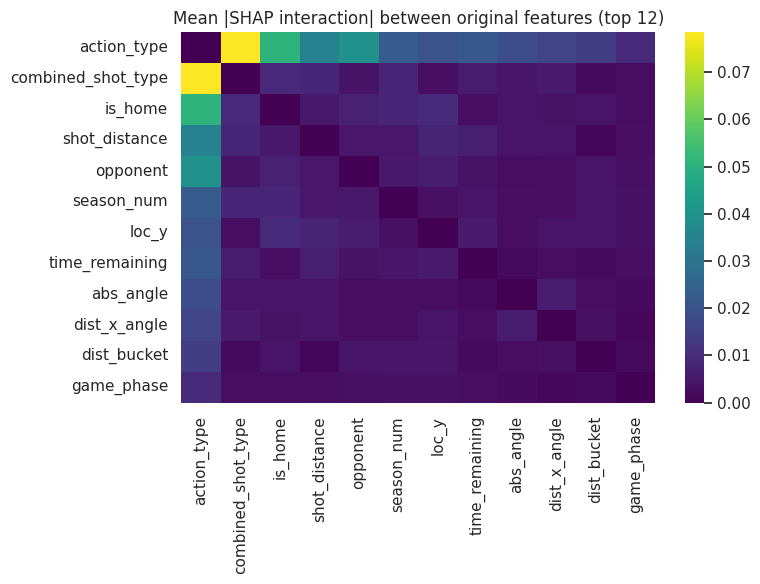

,feature_a,feature_b,interaction_strength
22,action_type,combined_shot_type,0.1568
26,action_type,is_home,0.1016
32,action_type,opponent,0.0787
37,action_type,shot_distance,0.0692
35,action_type,season_num,0.0447
42,action_type,time_remaining,0.0427
31,action_type,loc_y,0.0397
0,abs_angle,action_type,0.0365
24,action_type,dist_x_angle,0.0314
23,action_type,dist_bucket,0.0277


In [33]:
# Feature interaction analysis with SHAP interaction values (subsample for speed)
n_int = min(600, len(Xt))
inter = explainer.shap_interaction_values(Xt[:n_int])
if isinstance(inter, list): inter = inter[-1]
inter = np.asarray(inter)
if inter.ndim == 4: inter = inter[..., -1]

M_feat = np.abs(inter).mean(axis=0)                      # features x features
np.fill_diagonal(M_feat, 0.0)                            # keep only cross-feature (interaction) effects
group_names = sorted(set(orig_of.values()))
G = np.zeros((len(feat_names), len(group_names)))
for fi, fn in enumerate(feat_names):
    G[fi, group_names.index(orig_of[fn])] = 1.0
M_grp = G.T @ M_feat @ G
np.fill_diagonal(M_grp, 0.0)                             # drop within-group (e.g. one-hot siblings) effects
M_df = pd.DataFrame(M_grp, index=group_names, columns=group_names)

top_feats = M_df.sum(axis=1).sort_values(ascending=False).head(12).index
plt.figure(figsize=(8, 6)); sns.heatmap(M_df.loc[top_feats, top_feats], cmap="viridis", annot=False)
plt.title("Mean |SHAP interaction| between original features (top 12)"); plt.tight_layout(); plt.show()

pairs = [(a, b, 2 * M_df.loc[a, b]) for ai, a in enumerate(group_names) for b in group_names[ai + 1:]]
display(pd.DataFrame(pairs, columns=["feature_a", "feature_b", "interaction_strength"]).sort_values("interaction_strength", ascending=False).head(10).round(4))

In [34]:
# Stakeholder explainability report (plain language, generated from the SHAP results above)
top_groups = shap_orig.head(6)
lines = []
for g in top_groups.index:
    cols = [i for i, fn in enumerate(feat_names) if orig_of[fn] == g]
    if g in NUM:
        c = cols[0]
        r_ = np.corrcoef(Xt[:, c], sv[:, c])[0, 1] if np.std(Xt[:, c]) > 0 and np.std(sv[:, c]) > 0 else 0.0
        direction = ("higher values raise make-probability" if r_ > 0.1 else
                     "higher values lower make-probability" if r_ < -0.1 else "mixed / non-monotonic effect")
    else:
        eff = {}
        for c in cols:
            on = Xt[:, c] > 0.5
            if on.sum() >= 30:
                eff[feat_names[c][len(g) + 1:]] = float(sv[on, c].mean())
        s = pd.Series(eff).sort_values()
        if len(s) >= 4:
            direction = "raises make-probability: " + ", ".join(s.tail(2).index[::-1]) + "; lowers it: " + ", ".join(s.head(2).index)
        else:
            direction = "too few frequent categories in the sample to summarise"
    lines.append("* **" + g + "** (mean |SHAP| " + format(top_groups[g], ".3f") + "): " + direction)
display(Markdown("**What drives the model's make-probability (hold-out sample)**\n\n" + "\n".join(lines) +
                 "\n\n*These are associations learned by the model, not causal effects.*"))

order = ["0_4", "4_8", "8_16", "16_24", "24"]
dist_tab = (pd.DataFrame({"distance_ft": X_test["dist_bucket"].values, "model_p": final_p, "actual": y_test})
            .groupby("distance_ft").agg(shots=("actual", "size"), mean_model_prob=("model_p", "mean"), actual_fg=("actual", "mean"))
            .reindex([o for o in order if o in set(X_test["dist_bucket"])]).round(3))
display(dist_tab)

**What drives the model's make-probability (hold-out sample)**

* **action_type** (mean |SHAP| 0.788): raises make-probability: Pullup_Jump_shot, Driving_Layup_Shot; lowers it: Layup_Shot, Jump_Shot
* **combined_shot_type** (mean |SHAP| 0.132): too few frequent categories in the sample to summarise
* **shot_distance** (mean |SHAP| 0.065): higher values raise make-probability
* **loc_y** (mean |SHAP| 0.058): higher values raise make-probability
* **opponent** (mean |SHAP| 0.056): raises make-probability: NYK, PHX; lowers it: OKC, HOU
* **season_num** (mean |SHAP| 0.048): mixed / non-monotonic effect

*These are associations learned by the model, not causal effects.*

,shots,mean_model_prob,actual_fg
distance_ft,,,
0_4,1007,0.592,0.613
4_8,449,0.475,0.428
8_16,1268,0.486,0.442
16_24,1677,0.426,0.366
24,878,0.367,0.268


## 17. Error analysis

In [35]:
ea = lab.iloc[test_idx].copy()
ea["proba"], ea["pred"] = final_p, pred_te
ea["correct"] = (ea["pred"] == ea["shot_made_flag"]).astype(int)

print("Accuracy by shot zone (hold-out):")
display(ea.groupby("shot_zone_basic").agg(n=("correct", "size"), accuracy=("correct", "mean"), actual_fg=("shot_made_flag", "mean"), mean_pred=("proba", "mean")).round(3).sort_values("n", ascending=False))
print("Accuracy by action type (>= 40 shots):")
t = ea.groupby("action_type").agg(n=("correct", "size"), accuracy=("correct", "mean"), actual_fg=("shot_made_flag", "mean"))
display(t[t.n >= 40].round(3).sort_values("accuracy"))
print("Most confident wrong predictions:")
display(ea[ea.correct == 0].assign(conf=lambda d: (d.proba - .5).abs()).sort_values("conf", ascending=False)
        [["game_date", "action_type", "shot_distance", "shot_zone_basic", "period", "proba", "shot_made_flag"]].head(8).round(3))

Accuracy by shot zone (hold-out):


,n,accuracy,actual_fg,mean_pred
shot_zone_basic,,,,
Mid-Range,2058,0.585,0.402,0.456
Above the Break 3,1229,0.573,0.290,0.380
Restricted Area,920,0.686,0.626,0.601
In The Paint (Non-RA),881,0.664,0.454,0.495
Right Corner 3,106,0.585,0.302,0.357
Left Corner 3,78,0.615,0.346,0.356
Backcourt,7,1.000,0.000,0.030


Accuracy by action type (>= 40 shots):


,n,accuracy,actual_fg
action_type,,,
Fadeaway Jump Shot,312,0.484,0.494
Layup Shot,313,0.514,0.495
Turnaround Jump Shot,203,0.517,0.502
Turnaround Fadeaway shot,223,0.534,0.543
Step Back Jump shot,68,0.559,0.574
Jump Shot,3092,0.618,0.289
Jump Bank Shot,74,0.649,0.649
Running Jump Shot,63,0.651,0.651
Floating Jump shot,46,0.652,0.652


Most confident wrong predictions:


,game_date,action_type,shot_distance,shot_zone_basic,period,proba,shot_made_flag
24096,2013-04-12,Reverse Dunk Shot,1,Restricted Area,1,0.925,0
21709,2012-01-20,Alley Oop Dunk Shot,0,Restricted Area,1,0.919,0
24959,2015-12-01,Fadeaway Jump Shot,20,Mid-Range,2,0.919,0
24951,2015-12-01,Turnaround Fadeaway shot,14,Mid-Range,1,0.910,0
25374,2016-02-08,Pullup Jump shot,25,Above the Break 3,3,0.874,0
22325,2012-03-21,Pullup Bank shot,7,In The Paint (Non-RA),1,0.865,0
23601,2013-01-30,Turnaround Bank shot,7,In The Paint (Non-RA),3,0.863,0
25548,2016-03-27,Pullup Jump shot,16,Mid-Range,3,0.858,0


## 18. Model Comparison Report (deliverable) and production recommendation

In [36]:
all_rows = []
for n in cand_all:
    thr_n = float(sel_raw.loc[n, "threshold"])           # each model's own development-set threshold
    cvm = evaluate(y_dev, OOF[n], thr_n)
    tem = evaluate(y_test, TEST_P[n], thr_n)
    all_rows.append({"model": n, "CV selection score": sel_raw.loc[n, "selection_score"],
                     "CV accuracy": cvm["accuracy"], "CV F1": cvm["f1"], "CV AUC": cvm["roc_auc"], "CV log-loss": cvm["log_loss"],
                     "Hold-out accuracy": tem["accuracy"], "Hold-out F1": tem["f1"], "Hold-out AUC": tem["roc_auc"], "Hold-out log-loss": tem["log_loss"]})
report = pd.DataFrame(all_rows).set_index("model").round(4).sort_values("CV selection score", ascending=False)
display(report)

best_hold = report["Hold-out accuracy"].idxmax()
lr_hold = report.loc["Logistic Regression", "Hold-out accuracy"]
display(Markdown(f'''
### Recommendation
* **Selected for production: `{BEST_NAME}`** with {CAL_METHOD} probability calibration and decision threshold **{THR:.2f}**. The choice used the predefined SelectionScore = (Accuracy + F1)/2 on development-set cross-validation (ties within {TIE} broken by log-loss); calibration and threshold were also chosen on development data only.
* **Hold-out performance (future games, threshold {THR:.2f}):** accuracy **{final_tuned['accuracy']:.3f}**, F1 **{final_tuned['f1']:.3f}**, ROC-AUC **{final_tuned['roc_auc']:.3f}**, log-loss {final_tuned['log_loss']:.3f}; majority-class baseline accuracy is {maj:.3f}.
* 95 % game-level bootstrap intervals are in Section 15 and paired model comparisons in Section 20 — differences that sit inside those intervals are not meaningful.
* For transparency: the model with the highest *hold-out* accuracy in the table is `{best_hold}`. It is **not** used for selection, because choosing on the hold-out would make the reported score optimistic.
* The interpretable baseline `Logistic Regression` has hold-out accuracy {lr_hold:.3f} (at its own threshold); if the gap to the selected model is within the paired-bootstrap interval in Section 20, the simpler model is a defensible production choice.

### Caveats
* Shot outcomes are inherently noisy (no defender distance, shot clock, fatigue, score margin in the data), so accuracy has a low ceiling; the probabilities are more useful than hard labels.
* The model is trained on Kobe Bryant's shots only; do not apply it to other players.
* Hold-out games are from his later career, so some drop vs random-split scores is expected (non-stationarity — see Section 24).
'''))

,CV selection score,CV accuracy,CV F1,CV AUC,CV log-loss,Hold-out accuracy,Hold-out F1,Hold-out AUC,Hold-out log-loss
model,,,,,,,,,
Extra Trees,0.6350,0.6672,0.6029,0.7080,0.6018,0.6494,0.5945,0.6942,0.6196
Random Forest,0.6349,0.6764,0.5934,0.7069,0.6031,0.6615,0.5936,0.6942,0.6184
Tuned XGBoost,0.6330,0.6569,0.6090,0.7109,0.6006,0.6602,0.6024,0.6976,0.6157
HistGradientBoosting,0.6326,0.6450,0.6202,0.7105,0.6001,0.6139,0.6021,0.6947,0.6176
LightGBM,0.6321,0.6635,0.6008,0.7095,0.6003,0.6577,0.5909,0.6960,0.6157
Stacking (nested),0.6320,0.6647,0.5993,0.7114,0.5992,0.6647,0.5948,0.6980,0.6165
Soft Voting,0.6313,0.6550,0.6075,0.7112,0.5996,0.6573,0.5986,0.6980,0.6154
Tuned LightGBM,0.6309,0.6622,0.5997,0.7100,0.6014,0.6640,0.5965,0.6962,0.6181
CatBoost,0.6305,0.6750,0.5860,0.7084,0.6005,0.6662,0.5862,0.6948,0.6184



### Recommendation
* **Selected for production: `HistGradientBoosting`** with none probability calibration and decision threshold **0.39**. The choice used the predefined SelectionScore = (Accuracy + F1)/2 on development-set cross-validation (ties within 0.003 broken by log-loss); calibration and threshold were also chosen on development data only.
* **Hold-out performance (future games, threshold 0.39):** accuracy **0.614**, F1 **0.602**, ROC-AUC **0.695**, log-loss 0.618; majority-class baseline accuracy is 0.580.
* 95 % game-level bootstrap intervals are in Section 15 and paired model comparisons in Section 20 — differences that sit inside those intervals are not meaningful.
* For transparency: the model with the highest *hold-out* accuracy in the table is `CatBoost`. It is **not** used for selection, because choosing on the hold-out would make the reported score optimistic.
* The interpretable baseline `Logistic Regression` has hold-out accuracy 0.636 (at its own threshold); if the gap to the selected model is within the paired-bootstrap interval in Section 20, the simpler model is a defensible production choice.

### Caveats
* Shot outcomes are inherently noisy (no defender distance, shot clock, fatigue, score margin in the data), so accuracy has a low ceiling; the probabilities are more useful than hard labels.
* The model is trained on Kobe Bryant's shots only; do not apply it to other players.
* Hold-out games are from his later career, so some drop vs random-split scores is expected (non-stationarity — see Section 24).


## 19. Prediction system — artifacts, probability-based predictor and scoring of the unlabelled rows (Task 3)

In [37]:
# Refit the selected components on ALL labelled data. Hyper-parameters, meta-weights, calibrator and threshold stay as selected on development data.
if BEST_NAME in SINGLE:
    use, mode = [BEST_NAME], "single"
elif BEST_NAME == "Soft Voting":
    use, mode = base_names, "vote"
else:
    use, mode = base_names, "stack"
final_models = {n: clone(SINGLE[n]).fit(FEATS, y) for n in use}

lookup_cols = ["loc_x", "loc_y", "shot_type", "shot_zone_area", "shot_zone_basic", "shot_zone_range"]
artifact = {
    "models": final_models, "mode": mode, "meta": meta_model if mode == "stack" else None,
    "calibrator": cal_final, "threshold": THR, "num_features": NUM, "cat_features": CAT,
    "name": BEST_NAME, "trained_on": "Kobe Bryant shots only (1996-2016)", "versions": VERSIONS,
    "choices": {c: sorted(lab[c].astype(str).unique().tolist()) for c in ["action_type", "combined_shot_type", "opponent"]},
    "court_lookup": lab[lookup_cols].sample(min(3000, len(lab)), random_state=SEED).reset_index(drop=True),
}
joblib.dump(artifact, "kobe_shot_model.joblib")
print("Saved kobe_shot_model.joblib | mode:", mode, "| calibration:", CAL_METHOD, "| components:", list(final_models))

predict_shot = lambda row: predict_shot_row(artifact, row)
example = lab.iloc[test_idx[0]].to_dict()
print("Example shot ->", predict_shot(example), "| actual:", "made" if example["shot_made_flag"] == 1 else "missed")

Saved kobe_shot_model.joblib | mode: single | calibration: none | components: ['HistGradientBoosting']
Example shot -> {'probability_of_scoring': 0.605, 'predicted': 'MADE', 'threshold': 0.385, 'model': 'HistGradientBoosting'} | actual: made


In [38]:
# Score the rows that had no label in the original file. They have no ground truth, so no accuracy can be computed for them.
unl = raw[raw["shot_made_flag"].isna()].copy()
if len(unl):
    pu = predict_artifact(artifact, build_features(unl)[NUM + CAT])
    out = pd.DataFrame({"shot_id": unl["shot_id"].values, "shot_made_probability": pu.round(4), "shot_made_flag_pred": (pu >= THR).astype(int)})
    out.to_csv("unlabelled_shot_predictions.csv", index=False)
    print(len(out), "predictions saved -> unlabelled_shot_predictions.csv | predicted make rate:", round(out.shot_made_flag_pred.mean(), 3))

5000 predictions saved -> unlabelled_shot_predictions.csv | predicted make rate: 0.474


## 20. Advanced model statistical comparison (paired bootstrap and McNemar)
Which differences between models are real? Hold-out games are resampled **as clusters** (whole games) and the *same* resample is scored for both models, giving a paired confidence interval for the metric difference. McNemar's exact test compares the two models' hard predictions. This analysis is **descriptive and made after selection** — it changes no decision. (McNemar treats shots as independent, so its p-values are somewhat optimistic; rely on the game-level bootstrap.)

In [39]:
def paired_bootstrap(p_a, p_b, thr_a, thr_b, n=N_BOOT, seed=SEED + 1):
    rng_ = np.random.default_rng(seed)
    idx_by = pd.Series(np.arange(len(y_test))).groupby(g_test).indices
    ks = np.array(list(idx_by.keys()))
    metrics = ["accuracy", "f1", "roc_auc", "log_loss"]
    diffs = []
    for _ in range(n):
        idx = np.concatenate([idx_by[k] for k in rng_.choice(ks, size=len(ks), replace=True)])
        if len(np.unique(y_test[idx])) < 2:
            continue
        ea_, eb_ = evaluate(y_test[idx], p_a[idx], thr_a), evaluate(y_test[idx], p_b[idx], thr_b)
        diffs.append([ea_[m] - eb_[m] for m in metrics])
    return metrics, np.array(diffs)

comparators = [c for c in ["Logistic Regression", "Tuned LightGBM", "Soft Voting"] if c != BEST_NAME]
rows, mc_rows = [], []
for c in comparators:
    thr_c = float(sel_raw.loc[c, "threshold"])
    metrics, d = paired_bootstrap(final_p, TEST_P[c], THR, thr_c)
    for j, m in enumerate(metrics):
        lo, hi = np.percentile(d[:, j], [2.5, 97.5])
        better = (d[:, j] < 0).mean() if m == "log_loss" else (d[:, j] > 0).mean()
        rows.append({"selected_minus": c, "metric": m, "mean_diff": d[:, j].mean(), "ci_2.5%": lo, "ci_97.5%": hi,
                     "P(selected better)": better, "CI excludes 0": bool(lo > 0 or hi < 0)})
    ok_a = ((final_p >= THR).astype(int) == y_test)
    ok_b = ((TEST_P[c] >= thr_c).astype(int) == y_test)
    tbl = [[int((ok_a & ok_b).sum()), int((ok_a & ~ok_b).sum())], [int((~ok_a & ok_b).sum()), int((~ok_a & ~ok_b).sum())]]
    mc_rows.append({"selected_vs": c, "only_selected_correct": tbl[0][1], "only_other_correct": tbl[1][0],
                    "mcnemar_exact_p": mcnemar(tbl, exact=True).pvalue})
display(pd.DataFrame(rows).round(4))
display(pd.DataFrame(mc_rows).round(4))
print("For log-loss a NEGATIVE difference favours the selected model; for the other metrics a POSITIVE one does.")

,selected_minus,metric,mean_diff,ci_2.5%,ci_97.5%,P(selected better),CI excludes 0
0,Logistic Regression,accuracy,-0.0228,-0.0340,-0.0129,0.000,True
1,Logistic Regression,f1,0.0096,-0.0015,0.0201,0.966,False
2,Logistic Regression,roc_auc,0.0095,0.0030,0.0167,0.994,True
3,Logistic Regression,log_loss,-0.0130,-0.0181,-0.0080,1.000,True
4,Tuned LightGBM,accuracy,-0.0501,-0.0602,-0.0395,0.000,True
5,Tuned LightGBM,f1,0.0055,-0.0054,0.0165,0.838,False
6,Tuned LightGBM,roc_auc,-0.0016,-0.0061,0.0029,0.240,False
7,Tuned LightGBM,log_loss,-0.0005,-0.0028,0.0020,0.636,False
8,Soft Voting,accuracy,-0.0435,-0.0537,-0.0318,0.000,True
9,Soft Voting,f1,0.0034,-0.0070,0.0146,0.726,False


,selected_vs,only_selected_correct,only_other_correct,mcnemar_exact_p
0,Logistic Regression,361,480,0.0
1,Tuned LightGBM,284,548,0.0
2,Soft Voting,283,512,0.0


For log-loss a NEGATIVE difference favours the selected model; for the other metrics a POSITIVE one does.


## 21. Nested cross-validation (unbiased estimate of the *tuning procedure*)
In Section 10 the hyper-parameters were chosen on the same development folds that later scored the model, which is slightly optimistic. Nested CV removes that bias: for each **outer** grouped fold, Optuna tunes LightGBM using only the outer-training games (inner grouped 3-fold), the threshold is chosen on inner out-of-fold predictions, and the result is scored on the untouched outer fold. Logistic regression gets the same treatment as a reference. The outer folds are the same `FOLDS` used elsewhere.

In [40]:
nested_rows = []
t0 = time.time()
for k, (tr_i, va_i) in enumerate(FOLDS):
    Xtr, ytr, gtr = X_dev.iloc[tr_i], y_dev[tr_i], g_dev[tr_i]
    Xva, yva = X_dev.iloc[va_i], y_dev[va_i]
    inn = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(Xtr, ytr, gtr))

    def objective(t):
        params = space_lgb(t); sc = []
        for a, b in inn:
            m = make_pipe(make_lgb(params)).fit(Xtr.iloc[a], ytr[a])
            sc.append(log_loss(ytr[b], m.predict_proba(Xtr.iloc[b])[:, 1]))
        return float(np.mean(sc))

    st = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED + k))
    st.optimize(objective, n_trials=N_NEST)
    for label, pipe in [("Tuned LightGBM (nested)", make_pipe(make_lgb(st.best_params))),
                        ("Logistic Regression (nested)", models["Logistic Regression"])]:
        oof_in = np.zeros(len(tr_i))
        for a, b in inn:
            oof_in[b] = fit_predict_pipe(pipe, Xtr.iloc[a], ytr[a], Xtr.iloc[b])
        thr_k, _ = best_threshold(ytr, oof_in)
        pv = fit_predict_pipe(pipe, Xtr, ytr, Xva)
        e = evaluate(yva, pv, thr_k)
        nested_rows.append({"fold": k, "model": label, "threshold": thr_k,
                            "inner_cv_logloss": st.best_value if "Tuned" in label else np.nan, **e})
print(f"Nested CV finished in {time.time()-t0:.0f}s ({N_NEST} Optuna trials per outer fold)")
nested = pd.DataFrame(nested_rows)
summary = nested.groupby("model")[["accuracy", "f1", "roc_auc", "log_loss"]].agg(["mean", "std"]).round(4)
display(summary)
opt = nested[nested.model.str.startswith("Tuned")]
print(f"Optimism of tuning on the same folds: inner-CV log-loss {opt['inner_cv_logloss'].mean():.4f} "
      f"vs outer (untouched) log-loss {opt['log_loss'].mean():.4f}")

Nested CV finished in 215s (8 Optuna trials per outer fold)


accuracy              f1         roc_auc          \
                                 mean     std    mean     std    mean     std   
model                                                                           
Logistic Regression (nested)   0.6795  0.0101  0.5708  0.0130  0.6991  0.0067   
Tuned LightGBM (nested)        0.6671  0.0100  0.5928  0.0239  0.7084  0.0108   

                             log_loss          
                                 mean     std  
model                                          
Logistic Regression (nested)   0.6065  0.0076  
Tuned LightGBM (nested)        0.6032  0.0103

Optimism of tuning on the same folds: inner-CV log-loss 0.6068 vs outer (untouched) log-loss 0.6032


## 22. Model calibration and reliability analysis (hold-out, after selection)
The calibration *method* was fixed in Section 13. Here its effect on unseen future games is checked: Brier score, log-loss, expected calibration error (ECE), calibration slope/intercept and decile reliability.

,brier,log_loss,ece
Uncalibrated,0.2146,0.6176,0.0462
Selected (none),0.2146,0.6176,0.0462


Calibration intercept -0.224 (ideal 0) | slope 0.947 (ideal 1; <1 = over-confident)
Brier skill score vs always predicting the base rate: 0.1191


,shots,mean_predicted,observed_rate
bin,,,
"(0.0225, 0.284]",528,0.237,0.178
"(0.284, 0.327]",528,0.308,0.299
"(0.327, 0.354]",528,0.342,0.324
"(0.354, 0.376]",528,0.366,0.307
"(0.376, 0.391]",530,0.384,0.323
"(0.391, 0.413]",525,0.399,0.356
"(0.413, 0.544]",528,0.469,0.451
"(0.544, 0.674]",528,0.617,0.545
"(0.674, 0.754]",528,0.714,0.631


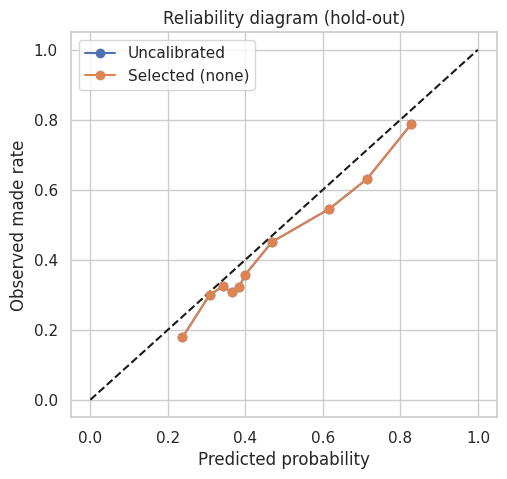

In [41]:
def cal_metrics(p):
    return {"brier": brier_score_loss(y_test, p), "log_loss": log_loss(y_test, np.clip(p, 1e-6, 1 - 1e-6)), "ece": ece(y_test, p)}

display(pd.DataFrame({"Uncalibrated": cal_metrics(final_raw), f"Selected ({CAL_METHOD})": cal_metrics(final_p)}).T.round(4))

fit_cal = sm.Logit(y_test, sm.add_constant(logit_feat(final_p))).fit(disp=0)
print(f"Calibration intercept {fit_cal.params[0]:.3f} (ideal 0) | slope {fit_cal.params[1]:.3f} (ideal 1; <1 = over-confident)")
bss = 1 - brier_score_loss(y_test, final_p) / (y_test.mean() * (1 - y_test.mean()))
print(f"Brier skill score vs always predicting the base rate: {bss:.4f}")

dec = (pd.DataFrame({"p": final_p, "y": y_test}).assign(bin=lambda d: pd.qcut(d.p, 10, duplicates="drop"))
       .groupby("bin", observed=True).agg(shots=("y", "size"), mean_predicted=("p", "mean"), observed_rate=("y", "mean")).round(3))
display(dec)

plt.figure(figsize=(5.5, 5)); plt.plot([0, 1], [0, 1], "k--")
for k, v in {"Uncalibrated": final_raw, f"Selected ({CAL_METHOD})": final_p}.items():
    fy, fx = calibration_curve(y_test, v, n_bins=10, strategy="quantile"); plt.plot(fx, fy, "o-", label=k)
plt.xlabel("Predicted probability"); plt.ylabel("Observed made rate"); plt.title("Reliability diagram (hold-out)"); plt.legend(); plt.show()

## 23. Advanced shot difficulty and spatial analysis
The model's probability is used as an **expected make-probability** (a *shot-difficulty* measure: low probability = hard shot). Comparing it with what actually happened shows where shots were made above or below expectation. Hold-out games only; descriptive, no selection.

,shots,actual_fg,expected_fg,over_expected,expected_pts_per_shot,actual_pts_per_shot,mean_difficulty
shot_zone_basic,,,,,,,
Restricted Area,920,0.626,0.601,0.025,1.202,1.252,0.399
Above the Break 3,1229,0.290,0.380,-0.091,1.141,0.869,0.620
Right Corner 3,106,0.302,0.357,-0.055,1.072,0.906,0.643
Left Corner 3,78,0.346,0.356,-0.010,1.069,1.038,0.644
In The Paint (Non-RA),881,0.454,0.495,-0.041,0.991,0.908,0.505
Mid-Range,2058,0.402,0.456,-0.054,0.912,0.804,0.544
Backcourt,7,0.000,0.030,-0.030,0.091,0.000,0.970


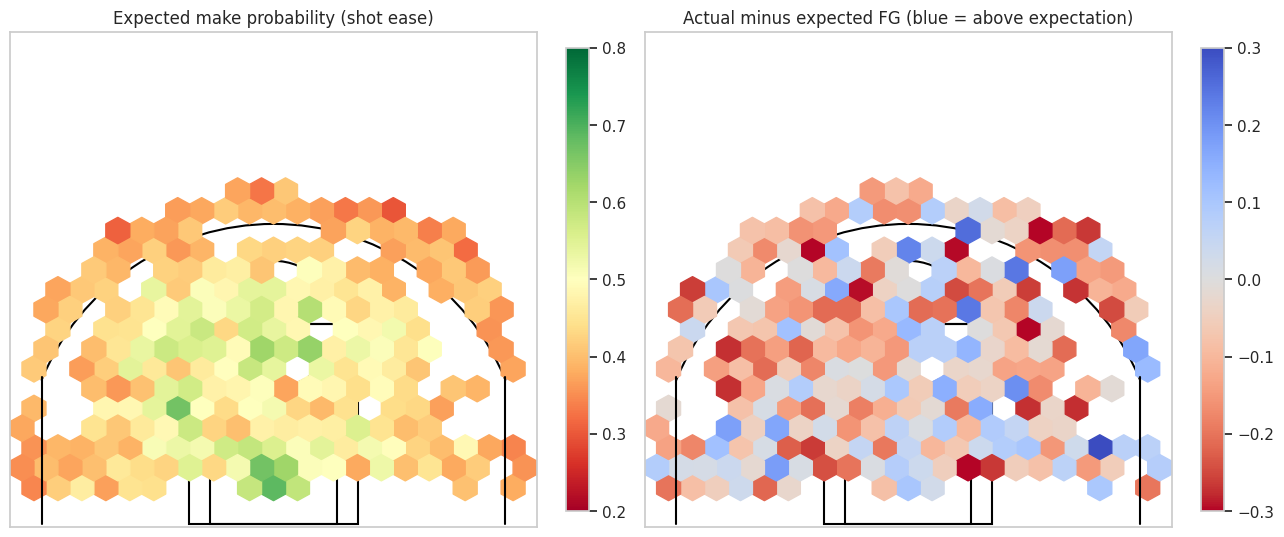

In [42]:
ho = lab.iloc[test_idx].copy()
ho["exp_fg"] = final_p
ho["difficulty"] = 1 - ho["exp_fg"]
ho["pts_value"] = np.where(ho["shot_type"].str.startswith("3"), 3, 2)
ho["exp_pts"] = ho["exp_fg"] * ho["pts_value"]
ho["act_pts"] = ho["shot_made_flag"] * ho["pts_value"]
ho["residual"] = ho["shot_made_flag"] - ho["exp_fg"]

zone = (ho.groupby("shot_zone_basic")
          .agg(shots=("residual", "size"), actual_fg=("shot_made_flag", "mean"), expected_fg=("exp_fg", "mean"),
               over_expected=("residual", "mean"), expected_pts_per_shot=("exp_pts", "mean"), actual_pts_per_shot=("act_pts", "mean"),
               mean_difficulty=("difficulty", "mean"))
          .sort_values("expected_pts_per_shot", ascending=False).round(3))
display(zone)

hc = ho[(ho.loc_y < 400) & (ho.loc_x.abs() < 250)]
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for a in ax: draw_court(a)
h1 = ax[0].hexbin(hc.loc_x, hc.loc_y, C=hc.exp_fg, reduce_C_function=np.mean, gridsize=22, mincnt=8, cmap="RdYlGn", vmin=.2, vmax=.8, extent=(-250, 250, -50, 400))
ax[0].set_title("Expected make probability (shot ease)"); plt.colorbar(h1, ax=ax[0], fraction=0.04)
h2 = ax[1].hexbin(hc.loc_x, hc.loc_y, C=hc.residual, reduce_C_function=np.mean, gridsize=22, mincnt=8, cmap="coolwarm_r", vmin=-.3, vmax=.3, extent=(-250, 250, -50, 400))
ax[1].set_title("Actual minus expected FG (blue = above expectation)"); plt.colorbar(h2, ax=ax[1], fraction=0.04)
plt.tight_layout(); plt.show()

In [43]:
# Interactive Plotly court: hover for distance, action and the model's make probability
def court_lines():
    th = np.linspace(0, np.pi, 100); full = np.linspace(0, 2 * np.pi, 100)
    a = np.arccos(220 / 237.5); t3 = np.linspace(a, np.pi - a, 150); ycorner = 237.5 * np.sin(a)
    return [(7.5 * np.cos(full), 7.5 * np.sin(full)), ([-30, 30], [-7.5, -7.5]),
            ([-80, -80, 80, 80], [-47.5, 142.5, 142.5, -47.5]), ([-60, -60, 60, 60], [-47.5, 142.5, 142.5, -47.5]),
            (60 * np.cos(th), 142.5 + 60 * np.sin(th)), (40 * np.cos(th), 40 * np.sin(th)),
            ([220, 220], [-47.5, ycorner]), ([-220, -220], [-47.5, ycorner]), (237.5 * np.cos(t3), 237.5 * np.sin(t3))]

s = hc.sample(min(2500, len(hc)), random_state=SEED)
fig = go.Figure()
fig.add_trace(go.Scatter(x=s.loc_x, y=s.loc_y, mode="markers",
                         marker=dict(size=5, color=s.exp_fg, colorscale="RdYlGn", cmin=.2, cmax=.8, colorbar=dict(title="P(make)")),
                         text=[f"{a} | {d} ft | P(make)={p:.2f} | {'made' if m else 'missed'}" for a, d, p, m in
                               zip(s.action_type, s.shot_distance, s.exp_fg, s.shot_made_flag)], hoverinfo="text", name="shots"))
for xs, ys in court_lines():
    fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines", line=dict(color="black", width=1), hoverinfo="skip", showlegend=False))
fig.update_xaxes(range=[250, -250], visible=False)
fig.update_yaxes(range=[-50, 420], visible=False, scaleanchor="x", scaleratio=1)
fig.update_layout(title="Shot difficulty map - hold-out shots coloured by model make-probability", height=620, width=560, plot_bgcolor="white")
fig.show()

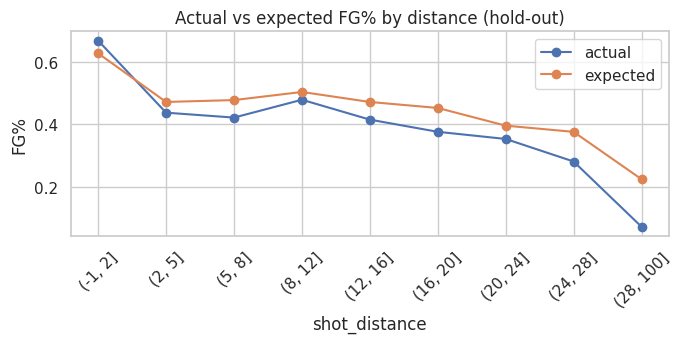

In [44]:
# Shot quality by distance: how closely does the model track the real make-rate curve?
b = pd.cut(ho.shot_distance, [-1, 2, 5, 8, 12, 16, 20, 24, 28, 100])
curve_d = ho.groupby(b, observed=True).agg(actual=("shot_made_flag", "mean"), expected=("exp_fg", "mean"))
curve_d.plot(marker="o", figsize=(7, 3.6)); plt.xticks(range(len(curve_d)), [str(i) for i in curve_d.index], rotation=45)
plt.title("Actual vs expected FG% by distance (hold-out)"); plt.ylabel("FG%"); plt.tight_layout(); plt.show()

## 24. Data and model drift analysis
Drift here means *development (earlier games) vs hold-out (later games)*, which is exactly what a deployed model faces. Three views:
1. **Feature drift** – Population Stability Index (PSI) and KS / chi-square tests per feature (PSI < 0.1 stable, 0.1 – 0.25 moderate, > 0.25 major).
2. **Target and prediction drift** – shift in make-rate and in mean predicted probability.
3. **Performance drift** – accuracy / AUC / log-loss of the final model by season.

An **Evidently AI** HTML report is also produced when the package is available.

In [45]:
def psi_numeric(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-4, None)
    c = np.clip(np.histogram(cur, edges)[0] / len(cur), 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

def psi_cat(ref, cur):
    cats = sorted(set(ref) | set(cur))
    r = ref.value_counts(normalize=True).reindex(cats).fillna(0).clip(lower=1e-4)
    c = cur.value_counts(normalize=True).reindex(cats).fillna(0).clip(lower=1e-4)
    return float(np.sum((c - r) * np.log(c / r)))

drift_rows = []
for col in NUM:
    ks = stats.ks_2samp(X_dev[col], X_test[col])
    drift_rows.append({"feature": col, "type": "numeric", "PSI": psi_numeric(X_dev[col].values, X_test[col].values), "test_p_value": ks.pvalue})
for col in CAT:
    cats = sorted(set(X_dev[col]) | set(X_test[col]))
    tab = np.array([X_dev[col].value_counts().reindex(cats).fillna(0).values, X_test[col].value_counts().reindex(cats).fillna(0).values])
    tab = tab[:, tab.sum(axis=0) > 0]
    drift_rows.append({"feature": col, "type": "categorical", "PSI": psi_cat(X_dev[col], X_test[col]), "test_p_value": stats.chi2_contingency(tab)[1]})
drift = pd.DataFrame(drift_rows).sort_values("PSI", ascending=False)
drift["status"] = pd.cut(drift["PSI"], [-1, 0.1, 0.25, 100], labels=["stable", "moderate", "major"])
display(drift.round(4))

print(f"Target drift    : FG% dev {y_dev.mean():.3f} -> hold-out {y_test.mean():.3f}")
print(f"Prediction drift: mean predicted P(make) dev (out-of-fold) {cal_oof_final.mean():.3f} -> hold-out {final_p.mean():.3f}")

,feature,type,PSI,test_p_value,status
12,season_num,numeric,8.0684,0.0000,major
20,opponent,categorical,0.5444,0.0000,major
3,shot_angle,numeric,0.3739,0.0000,major
14,action_type,categorical,0.3704,0.0000,major
0,loc_x,numeric,0.3013,0.0000,major
1,loc_y,numeric,0.2529,0.0000,major
4,abs_angle,numeric,0.2157,0.0000,moderate
5,dist_x_angle,numeric,0.0993,0.0000,stable
15,combined_shot_type,categorical,0.0596,0.0000,stable
18,shot_zone_basic,categorical,0.0580,0.0000,stable


Target drift    : FG% dev 0.453 -> hold-out 0.420
Prediction drift: mean predicted P(make) dev (out-of-fold) 0.453 -> hold-out 0.466


,shots,actual_fg,mean_pred,accuracy,auc,log_loss
season,,,,,,
2010-11,951,0.450,0.459,0.610,0.683,0.624
2011-12,1416,0.426,0.453,0.622,0.678,0.628
2012-13,1328,0.458,0.484,0.645,0.738,0.592
2013-14,59,0.407,0.457,0.576,0.717,0.582
2014-15,593,0.376,0.451,0.594,0.682,0.614
2015-16,932,0.356,0.479,0.577,0.685,0.636


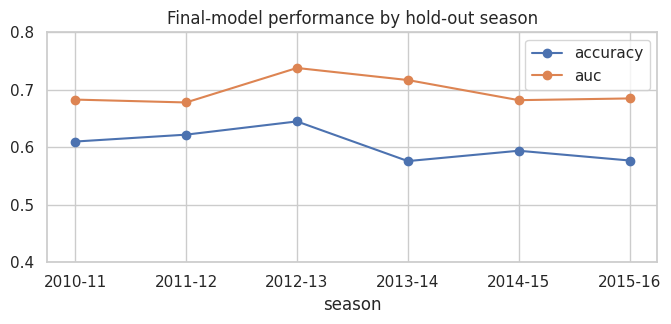

In [46]:
perf = []
for sn, d in ho.groupby(ho["season"]):
    pr_ = (d["exp_fg"] >= THR).astype(int)
    perf.append({"season": sn, "shots": len(d), "actual_fg": d.shot_made_flag.mean(), "mean_pred": d.exp_fg.mean(),
                 "accuracy": accuracy_score(d.shot_made_flag, pr_),
                 "auc": roc_auc_score(d.shot_made_flag, d.exp_fg) if d.shot_made_flag.nunique() > 1 else np.nan,
                 "log_loss": log_loss(d.shot_made_flag, np.clip(d.exp_fg, 1e-6, 1 - 1e-6), labels=[0, 1])})
perf = pd.DataFrame(perf).set_index("season").round(3)
display(perf)
perf[["accuracy", "auc"]].plot(marker="o", figsize=(7, 3.4)); plt.title("Final-model performance by hold-out season"); plt.ylim(0.4, 0.8); plt.tight_layout(); plt.show()

In [47]:
# Evidently AI drift report (optional; supports both the current and the legacy API)
cols_ev = NUM + CAT
try:
    try:
        from evidently import Report
        from evidently.presets import DataDriftPreset
        snap = Report([DataDriftPreset()]).run(current_data=X_test[cols_ev], reference_data=X_dev[cols_ev])
        snap.save_html("evidently_drift_report.html")
    except ImportError:
        from evidently.report import Report
        from evidently.metric_preset import DataDriftPreset
        rep = Report(metrics=[DataDriftPreset()])
        rep.run(reference_data=X_dev[cols_ev], current_data=X_test[cols_ev])
        rep.save_html("evidently_drift_report.html")
    print("Evidently report saved -> evidently_drift_report.html")
except Exception as e:
    print("Evidently report skipped:", repr(e)[:200])
    print("Known cause: Evidently 0.7.x does not yet import under pandas 3.x. It works with pandas 2.x (e.g. the default Colab runtime), "
          "or install it into an environment with pandas<3.")
    print("The PSI / KS analysis above covers the same ground, so no result in this notebook depends on Evidently.")

Evidently report saved -> evidently_drift_report.html


## 25. Production architecture and MLOps roadmap
```
 raw shot record ──► Pandera input contract ──► build_features (shared source) ──► model artifact (joblib)
                                                                                        │
        ┌─────────────── FastAPI  POST /predict ◄──────────────────────────────────────┤
        │                 returns probability, decision, model name, threshold          │
        ├─────────────── Streamlit dashboard (interactive shot predictor)               │
        └─────────────── monitoring: PSI / Evidently drift + accuracy by period ◄───────┘
                         MLflow tracks every experiment, parameter, metric and artifact
```
This section (a) logs the experiments with **MLflow**, (b) writes the deployable files, and (c) checks that the deployed code reproduces the notebook's predictions. The FastAPI and Streamlit files are optional extras; the graded deliverable remains this notebook.

In [48]:
# (a) Experiment tracking with MLflow (local SQLite backend)
try:
    import mlflow
    clean = lambda k: re.sub(r"[^0-9A-Za-z_.\- /]+", "_", str(k))
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("kobe-shot-prediction")
    tuned_params = {"Tuned XGBoost": STUDIES["XGBoost"][0].best_params, "Tuned LightGBM": STUDIES["LightGBM"][0].best_params}
    for name, r_ in report.iterrows():
        with mlflow.start_run(run_name=name):
            mlflow.log_param("model", name)
            mlflow.log_param("validation", "StratifiedGroupKFold(5) on earlier games + chronological hold-out")
            mlflow.log_param("selection_score", "(accuracy + F1) / 2")
            for k, v in tuned_params.get(name, {}).items():
                mlflow.log_param("hp_" + k, v)
            mlflow.log_metrics({clean(k): float(v) for k, v in r_.items() if pd.notna(v)})
    with mlflow.start_run(run_name="FINAL_" + BEST_NAME):
        mlflow.log_params({"selected_model": BEST_NAME, "threshold": round(THR, 3), "calibration": CAL_METHOD, "ensemble_mode": mode})
        mlflow.log_metrics({"holdout_" + k: float(v) for k, v in final_tuned.items()})
        mlflow.log_artifact("kobe_shot_model.joblib")
        mlflow.log_dict(VERSIONS, "package_versions.json")
    print("MLflow: logged", len(report) + 1, "runs to mlflow.db (experiment 'kobe-shot-prediction'). View with: mlflow ui --backend-store-uri sqlite:///mlflow.db")
except Exception as e:
    print("MLflow logging skipped:", repr(e)[:300])

2026/11/10 17:32:09 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 17:32:09 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 17:32:11 INFO mlflow.tracking.fluent: Experiment with name 'kobe-shot-prediction' does not exist. Creating a new experiment.


MLflow: logged 12 runs to mlflow.db (experiment 'kobe-shot-prediction'). View with: mlflow ui --backend-store-uri sqlite:///mlflow.db


In [49]:
# (b) Deployable files. shot_service.py reuses the exact feature/prediction source executed in this notebook.
SERVICE_HEADER = "import numpy as np\nimport pandas as pd\nimport joblib\n\n"
SERVICE_LOAD = '''
def load_artifact(path="kobe_shot_model.joblib"):
    return joblib.load(path)
'''
pathlib.Path("shot_service.py").write_text(SERVICE_HEADER + FEATURE_SRC + "\n" + PREDICT_SRC + "\n" + SERVICE_LOAD)

API_SRC = '''
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from shot_service import load_artifact, predict_shot_row

app = FastAPI(title="Kobe Bryant historical shot predictor",
              description="Trained on Kobe Bryant shots only (1996-2016). Not valid for other players.")
art = load_artifact()

class Shot(BaseModel):
    action_type: str
    combined_shot_type: str
    loc_x: int
    loc_y: int
    shot_distance: int
    period: int
    playoffs: int
    minutes_remaining: int
    seconds_remaining: int
    season: str
    matchup: str
    opponent: str
    shot_type: str
    shot_zone_area: str
    shot_zone_basic: str
    shot_zone_range: str

@app.get("/health")
def health():
    return {"status": "ok", "model": art["name"], "threshold": art["threshold"]}

@app.post("/predict")
def predict(shot: Shot):
    row = shot.model_dump() if hasattr(shot, "model_dump") else shot.dict()
    try:
        return predict_shot_row(art, row)
    except ValueError as e:
        raise HTTPException(status_code=422, detail=str(e))
'''
pathlib.Path("api.py").write_text(API_SRC)

DASH_SRC = '''
import numpy as np
import streamlit as st
from shot_service import load_artifact, predict_shot_row

st.set_page_config(page_title="Kobe shot predictor", layout="centered")
st.title("Kobe Bryant - historical shot predictor")
st.caption("Trained on Kobe Bryant's shots only (1996-2016). Not valid for other players.")

@st.cache_resource
def get_art():
    return load_artifact()

art = get_art()
lookup = art["court_lookup"]
choices = art["choices"]

c1, c2 = st.columns(2)
loc_x = c1.slider("loc_x (tenths of ft from hoop, left/right)", -250, 250, 0)
loc_y = c1.slider("loc_y (tenths of ft from hoop, depth)", -40, 400, 100)
action = c2.selectbox("Action type", choices["action_type"])
combined = c2.selectbox("Combined shot type", choices["combined_shot_type"])
opponent = c2.selectbox("Opponent", choices["opponent"])
period = c1.selectbox("Period", [1, 2, 3, 4, 5], index=0)
minutes = c1.slider("Minutes remaining", 0, 11, 6)
seconds = c1.slider("Seconds remaining", 0, 59, 30)
playoffs = c2.checkbox("Playoffs", value=False)
home = c2.checkbox("Home game", value=True)

# zone labels are borrowed from the nearest historical shot, so they stay consistent with the data
nearest = lookup.iloc[int(np.argmin((lookup["loc_x"] - loc_x) ** 2 + (lookup["loc_y"] - loc_y) ** 2))]
dist = int(round(float(np.hypot(loc_x, loc_y)) / 10))
row = {"action_type": action, "combined_shot_type": combined, "loc_x": loc_x, "loc_y": loc_y, "shot_distance": dist,
       "period": period, "playoffs": int(playoffs), "minutes_remaining": minutes, "seconds_remaining": seconds,
       "season": "2012-13", "matchup": ("LAL vs. " if home else "LAL @ ") + opponent, "opponent": opponent,
       "shot_type": nearest["shot_type"], "shot_zone_area": nearest["shot_zone_area"],
       "shot_zone_basic": nearest["shot_zone_basic"], "shot_zone_range": nearest["shot_zone_range"]}
res = predict_shot_row(art, row)
st.metric("Probability of scoring", f"{res['probability_of_scoring']:.1%}")
st.write("Decision at threshold", res["threshold"], "->", res["predicted"])
st.caption(f"Distance {dist} ft | zone: {row['shot_zone_basic']} | model: {res['model']}")
'''
pathlib.Path("dashboard.py").write_text(DASH_SRC)

req = [f"{k}=={v}" for k, v in VERSIONS.items() if k in ["numpy", "pandas", "scikit-learn", "xgboost", "lightgbm", "catboost", "joblib"] and v != "not installed"]
req += ["fastapi", "uvicorn", "streamlit"]
pathlib.Path("requirements.txt").write_text("\n".join(req) + "\n")
pathlib.Path("Dockerfile").write_text(
    "FROM python:3.11-slim\nWORKDIR /app\nCOPY requirements.txt .\nRUN pip install --no-cache-dir -r requirements.txt\n"
    "COPY shot_service.py api.py dashboard.py kobe_shot_model.joblib ./\nEXPOSE 8000\n"
    "CMD [\"uvicorn\", \"api:app\", \"--host\", \"0.0.0.0\", \"--port\", \"8000\"]\n")
print("Wrote: shot_service.py, api.py, dashboard.py, requirements.txt, Dockerfile")

Wrote: shot_service.py, api.py, dashboard.py, requirements.txt, Dockerfile


In [50]:
# (c) Check that the deployed code reproduces the notebook predictions exactly
sys.path.insert(0, os.getcwd())
import importlib, shot_service
importlib.reload(shot_service)
art2 = shot_service.load_artifact("kobe_shot_model.joblib")
rows_chk = [lab.iloc[i].to_dict() for i in test_idx[:25]]
a = np.array([predict_shot(r)["probability_of_scoring"] for r in rows_chk])
b = np.array([shot_service.predict_shot_row(art2, r)["probability_of_scoring"] for r in rows_chk])
print("Max abs difference notebook vs shot_service.py on 25 shots:", float(np.abs(a - b).max()))
assert np.allclose(a, b), "deployed service disagrees with notebook"

# Pandera contract also applies to incoming single-shot requests
try:
    schema.validate(pd.DataFrame([{**rows_chk[0], "game_date": pd.Timestamp(rows_chk[0]["game_date"])}]), lazy=True)
    print("Pandera: sample request satisfies the data contract.")
except Exception as e:
    print("Pandera flagged the sample request:", str(e)[:200])

Max abs difference notebook vs shot_service.py on 25 shots: 0.0
Pandera: sample request satisfies the data contract.


### MLOps roadmap (beyond this assignment)
| Step | What | Tooling |
|---|---|---|
| Containerise | Build and run the API image | `docker build -t kobe-shot . && docker run -p 8000:8000 kobe-shot` |
| Serve | `POST /predict`, `GET /health` | FastAPI + Uvicorn (`api.py`) |
| Explore | Interactive shot predictor | Streamlit (`streamlit run dashboard.py`) |
| Track | Compare experiments, register the final model | MLflow (`mlflow ui --backend-store-uri sqlite:///mlflow.db`) |
| Monitor | Weekly PSI / Evidently report on incoming shots; alert when PSI > 0.25 or accuracy falls below the majority baseline | Section 24 code, Evidently |
| Retrain | Rebuild when drift alerts fire or new seasons arrive, repeating Sections 8 – 15 | CI job running this notebook |

Scope reminder: the model was trained on Kobe Bryant's shots only. Using it for other players would require new data and re-validation.

## 26. Report on Challenges Faced

| # | Challenge | Technique used | Why |
|---|---|---|---|
| 1 | **~5,000 rows have no target** (`shot_made_flag` empty) | Set aside for training/evaluation; scored by the final model in Section 19; exploratory missingness check (Section 3) | A supervised model cannot learn from or be scored against rows with no label, but the trained model *can* predict them. The check only compares observed columns, so it cannot prove the missingness is random. |
| 2 | **Optimistic scores from random splits** — shots from one game share context | Compared random / group / chronological splits; `StratifiedGroupKFold`; chronological hold-out | A random split lets the model see the test game's other shots; the chronological hold-out mimics predicting future shots. |
| 3 | **Leakage inside stacking** — meta-model validated on base predictions from models that had seen the validation fold | Nested, group-aware cross-fitting (Section 11); soft voting as the simple alternative | Removes the hidden information path so the stack's validation score is honest. |
| 4 | **Calibration method chosen on the hold-out** would contradict "hold-out used once" | Calibration compared by cross-fitting on development out-of-fold predictions (Section 13); the hold-out only evaluates the already-chosen method (Section 22) | Keeps every selection decision independent of the final test data. |
| 5 | **Selection metric did not match the assignment** (log-loss vs accuracy/F1) | Predefined SelectionScore = (Accuracy + F1)/2 with a fixed tie rule; log-loss/AUC as secondary criteria (Section 12) | Aligns model choice with the stated goal while avoiding post-hoc cherry-picking. |
| 6 | **Optimistic scores after tuning on the same folds** | Nested CV (Section 21) | Measures how much hyper-parameter search inflates CV scores. |
| 7 | **Redundant / useless columns** — `lat`,`lon`, constant `team_id`,`team_name`, `matchup` | VIF and uniqueness checks; dropped or re-encoded (`is_home`) | Removes multicollinearity and noise; keeps SHAP interpretation clean. |
| 8 | **Identifier-like columns** (`shot_id`, `game_event_id`, `game_id`) | Not used as features; `game_id` only as the CV grouping key | They encode ordering/identity, not shot circumstances. |
| 9 | **High-cardinality categoricals** (`action_type`, `opponent`) | One-hot with `min_frequency=20` | Avoids unstable columns for levels with a handful of shots. |
| 10 | **Special characters** in category text broke XGBoost/LightGBM | Sanitised category strings | Library restriction on feature-name characters. |
| 11 | **Mild class imbalance** | Checked the ratio; probability outputs + threshold tuning on out-of-fold data instead of SMOTE/under-sampling | Classes are nearly balanced; synthetic basketball shots can be unrealistic. The threshold maximises the mean of accuracy and F1 because F1 on the positive class alone can be gamed. |
| 11b | **Genuine outliers** (back-court heaves) | IQR + Isolation Forest flagging; **kept** | Real events, not errors; trees are robust to them. |
| 12 | **Very noisy target** (no defender, shot-clock, fatigue, score margin) | Majority-class baseline, log-loss/AUC, calibration, bootstrap CIs, paired tests | Accuracy alone is a weak yardstick; intervals show which differences are real. |
| 13 | **Non-stationarity** over a 20-year career | Chronological evaluation; `season_num`; drift analysis (Section 24) | Training on the past and testing on the future exposes drift honestly. |
| 14 | **No true shot clock** | Feature named `last_5s` (game clock) and documented | Avoids claiming information the data does not contain. |
| 15 | **Black-box models** | SHAP (global, local, interactions) + permutation importance + plain-language report | Gives stakeholders reasons for predictions; importance is not causation. |
| 16 | **Reproducibility** — missing install dependencies, unrecorded versions, notebook/service drift | Explicit `%pip install` of every import, recorded versions + `requirements_used.txt`, feature code shared with `shot_service.py` and checked for identical predictions | The notebook runs in a fresh environment and the deployed code matches it. |
| 17 | **Bad input data in production** | Pandera data contract on raw data and on incoming requests | Detects invalid values before they reach the model. |

## 27. Stakeholder insights for game strategy (Task 2)
All numbers below are computed from the data; the strategic reading is conditional on the pattern holding for the player/era studied.

In [51]:
def top_bottom(col, min_n=300, k=3):
    t = lab.groupby(col)["shot_made_flag"].agg(n="size", fg="mean")
    t = t[t.n >= min_n].sort_values("fg", ascending=False)
    return t.head(k), t.tail(k)

zb_top, zb_bot = top_bottom("shot_zone_basic")
at_top, at_bot = top_bottom("action_type", 300, 3)
pts = lab.assign(pts=np.where(lab.shot_type.str.startswith("3"), 3, 2) * lab.shot_made_flag)
ppa = pts.groupby("shot_zone_basic").agg(attempts=("pts", "size"), fg=("shot_made_flag", "mean"), points_per_shot=("pts", "mean")).sort_values("points_per_shot", ascending=False).round(3)
display(ppa)
late = lab[lab.minutes_remaining * 60 + lab.seconds_remaining <= 24]

def fmt(t):
    return ", ".join("**" + str(i) + "** (" + format(r.fg, ".1%") + ")" for i, r in t.iterrows())

zb_top_s, zb_bot_s, at_top_s, at_bot_s = fmt(zb_top), fmt(zb_bot), fmt(at_top), fmt(at_bot)
display(Markdown(f'''
**What the data says**
* Highest-efficiency zones (>=300 attempts): {zb_top_s}; lowest: {zb_bot_s}.
* Best action types (>=300 attempts): {at_top_s}; weakest: {at_bot_s}.
* Points per shot (table above) combines make-rate with shot value, the right yardstick for comparing 2- and 3-point zones.
* Final 24 seconds of a period: FG% {late.shot_made_flag.mean():.1%} on {len(late)} attempts vs {lab.shot_made_flag.mean():.1%} overall.

**How to use it**
* *Offence:* prefer creating attempts from the highest points-per-shot zones/actions; use the model's probability (Section 23) to flag low-probability attempts that could be traded for better looks.
* *Defence (opponents):* the SHAP dependence plots and the shot-difficulty map show where make-probability falls fastest and which actions are hardest to convert — defensive schemes can target those.
* *Caution:* the model sees shot *circumstances*, not defender pressure or shot-clock; treat it as a decision aid, not an oracle.
'''))

,attempts,fg,points_per_shot
shot_zone_basic,,,
Restricted Area,5932,0.618,1.236
Left Corner 3,240,0.371,1.112
Right Corner 3,333,0.339,1.018
Above the Break 3,4720,0.329,0.988
In The Paint (Non-RA),3880,0.454,0.909
Mid-Range,10532,0.406,0.815
Backcourt,60,0.017,0.050



**What the data says**
* Highest-efficiency zones (>=300 attempts): **Restricted Area** (61.8%), **In The Paint (Non-RA)** (45.4%), **Mid-Range** (40.6%); lowest: **Mid-Range** (40.6%), **Right Corner 3** (33.9%), **Above the Break 3** (32.9%).
* Best action types (>=300 attempts): **Slam Dunk Shot** (98.2%), **Running Jump Shot** (74.7%), **Driving Layup Shot** (74.1%); weakest: **Fadeaway Jump Shot** (57.5%), **Layup Shot** (38.5%), **Jump Shot** (32.7%).
* Points per shot (table above) combines make-rate with shot value, the right yardstick for comparing 2- and 3-point zones.
* Final 24 seconds of a period: FG% 32.3% on 1589 attempts vs 44.6% overall.

**How to use it**
* *Offence:* prefer creating attempts from the highest points-per-shot zones/actions; use the model's probability (Section 23) to flag low-probability attempts that could be traded for better looks.
* *Defence (opponents):* the SHAP dependence plots and the shot-difficulty map show where make-probability falls fastest and which actions are hardest to convert — defensive schemes can target those.
* *Caution:* the model sees shot *circumstances*, not defender pressure or shot-clock; treat it as a decision aid, not an oracle.


## 28. Conclusion
* A complete analysis (Task 1), a leakage-aware model-selection workflow (Tasks 2 and 3), a **Model Comparison Report** (Section 18) and a **Challenges Report** (Section 26) are contained in this single notebook.
* Every selection decision — model (predefined accuracy/F1 score), calibration method, threshold, hyper-parameters, stacking — was made on development data with grouped, nested validation; the chronological hold-out was used only to *report* the chosen configuration.
* The production recommendation and its expected future-game performance (with confidence intervals and paired tests) are generated from the executed results, so they always match the outputs.
* Artifacts produced: `kobe_shot_model.joblib`, `unlabelled_shot_predictions.csv`, `shot_service.py`, `api.py`, `dashboard.py`, `requirements.txt`, `requirements_used.txt`, `Dockerfile`, MLflow runs in `mlflow.db`, and (if available) `evidently_drift_report.html`.

**Before submission:** run every cell top to bottom on the real dataset (Runtime ▸ Run all) and save the notebook **with its outputs**.

**Future scope:** player-tracking features (defender distance, shot clock, fatigue, score margin) from additional datasets; an AI strategy recommender built on expected points per shot; computer-vision shot detection from video — each needs data this project does not have.